# Home Credit Default Risk

This notebook predicts the probability that a current loan application becomes severely delinquent in the early installments. The label is `TARGET` (1 means severe delinquency). The evaluation metric is ROC AUC. The training set has 307,511 applications and the positive class is about 8%, so accuracy is not used to choose models.

Three models are fit: LightGBM, CatBoost, and a LightGBM that takes a repayment-trajectory probability as an extra feature. Their out-of-fold probabilities are combined with logistic regression. 75% of the applications are used for training and model comparison. The remaining 25% is held out and scored only once, at the end.


## EDA


### Data checks


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight'}
import os
os.environ["OMP_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"] = "8"

import gc
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import psutil

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve,
)
from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, LinearRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 160
plt.rcParams["savefig.dpi"] = 220
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

ROOT = Path.cwd()
if not (ROOT / "data" / "application_train.csv").exists():
    ROOT = Path(r"e:\HKUST_DDM\MSDM5054\mini-project")
    os.chdir(ROOT)
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output" / "v3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_JOBS = 8
REBUILD_FEATURES = False
N_FOLDS = 5

print("Project directory:", ROOT)
print("Available memory: {:.1f} GB".format(psutil.virtual_memory().available / 1e9))
print("pandas", pd.__version__, "| numpy", np.__version__)


Project directory: e:\HKUST_DDM\MSDM5054\mini-project
Available memory: 13.8 GB
pandas 3.0.6 | numpy 2.4.6


In [2]:
def get_clf_eval(y_true, pred, pred_proba):
    y_true = np.asarray(y_true).astype(int)
    pred = np.asarray(pred).astype(int)
    pred_proba = np.asarray(pred_proba, dtype=float)
    confusion = confusion_matrix(y_true, pred)
    accuracy = accuracy_score(y_true, pred)
    precision = precision_score(y_true, pred, zero_division=0)
    recall = recall_score(y_true, pred, zero_division=0)
    f1 = f1_score(y_true, pred, zero_division=0)
    auc = roc_auc_score(y_true, pred_proba)
    print(
        "accuracy: {0:.4f}, precision: {1:.4f}, recall: {2:.4f}, F1: {3:.4f}, AUC: {4:.4f}".format(
            accuracy, precision, recall, f1, auc
        )
    )
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc,
        "confusion": confusion,
    }


def best_f1_threshold(y_true, proba):
    y_true = np.asarray(y_true).astype(int)
    proba = np.asarray(proba, dtype=float)
    thresholds = np.linspace(0.01, 0.99, 99)
    f1s = np.array([
        f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in thresholds
    ])
    idx = int(np.argmax(f1s))
    return float(thresholds[idx]), float(f1s[idx]), thresholds, f1s


def count_rows(filename, column):
    total = 0
    path = DATA_DIR / filename
    for chunk in pd.read_csv(path, usecols=[column], chunksize=1_000_000):
        total += len(chunk)
    return total


def sum_parts(parts):
    parts = [p for p in parts if p is not None and len(p)]
    if not parts:
        return pd.Series(dtype="float64")
    out = parts[0].astype("float64")
    for part in parts[1:]:
        out = out.add(part.astype("float64"), fill_value=0)
    return out


def extremum_parts(parts, how="max"):
    parts = [p for p in parts if p is not None and len(p)]
    if not parts:
        return pd.Series(dtype="float64")
    out = parts[0].astype("float64")
    fill = -np.inf if how == "max" else np.inf
    fn = np.maximum if how == "max" else np.minimum
    for part in parts[1:]:
        out = out.combine(part.astype("float64"), fn, fill_value=fill)
    return out.replace([np.inf, -np.inf], np.nan)


In [3]:
application = pd.read_csv(DATA_DIR / "application_train.csv")
application_test = pd.read_csv(DATA_DIR / "application_test.csv")

print("application_train:", application.shape)
print("application_test:", application_test.shape)
print("Train SK_ID_CURR is unique:", application["SK_ID_CURR"].is_unique)
print("Test SK_ID_CURR is unique:", application_test["SK_ID_CURR"].is_unique)
overlap = len(set(application["SK_ID_CURR"]).intersection(application_test["SK_ID_CURR"]))
print("Train/test primary-key overlap:", overlap)

target_rate = application["TARGET"].mean()
print("TARGET=1: {:,} / {:,}  ({:.2%})".format(
    int(application["TARGET"].sum()), len(application), target_rate
))

row_counts = [("application_train", len(application)), ("application_test", len(application_test))]
for filename, column in [
    ("bureau.csv", "SK_ID_CURR"),
    ("bureau_balance.csv", "SK_ID_BUREAU"),
    ("previous_application.csv", "SK_ID_CURR"),
    ("POS_CASH_balance.csv", "SK_ID_CURR"),
    ("credit_card_balance.csv", "SK_ID_CURR"),
    ("installments_payments.csv", "SK_ID_CURR"),
]:
    t0 = time.perf_counter()
    n = count_rows(filename, column)
    row_counts.append((filename, n))
    print("Counted {:28s} {:>12,} rows  {:.0f}s".format(filename, n, time.perf_counter() - t0))

display(pd.DataFrame(row_counts, columns=["table", "rows"]))


application_train: (307511, 122)
application_test: (48744, 121)
Train SK_ID_CURR is unique: True
Test SK_ID_CURR is unique: True
Train/test primary-key overlap: 0
TARGET=1: 24,825 / 307,511  (8.07%)


Counted bureau.csv                      1,716,428 rows  3s


Counted bureau_balance.csv             27,299,925 rows  9s


Counted previous_application.csv        1,670,214 rows  5s


Counted POS_CASH_balance.csv           10,001,358 rows  6s


Counted credit_card_balance.csv         3,840,312 rows  7s


Counted installments_payments.csv      13,605,401 rows  12s


,table,rows
0,application_train,307511
1,application_test,48744
2,bureau.csv,1716428
3,bureau_balance.csv,27299925
4,previous_application.csv,1670214
5,POS_CASH_balance.csv,10001358
6,credit_card_balance.csv,3840312
7,installments_payments.csv,13605401


The seven tables are aligned to the current application on `SK_ID_CURR`. `bureau_balance` attaches to bureau credit records through `SK_ID_BUREAU`. POS, credit-card, and installment tables attach to previous applications through `SK_ID_PREV`. Every timestamp is a day or month count relative to the current application date.


### Missing values and anomalies


,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.00,112500.00,147150.00,202500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,270000.00,513531.00,808650.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,16524.00,24903.00,34596.00,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.21,369446.46,40500.00,238500.00,450000.00,679500.00,4.050000e+06
DAYS_BIRTH,307511.0,-16037.00,4363.99,-25229.00,-19682.00,-15750.00,-12413.00,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.00,-2760.00,-1213.00,-289.00,3.652430e+05
EXT_SOURCE_1,134133.0,0.50,0.21,0.01,0.33,0.51,0.68,9.600000e-01
EXT_SOURCE_2,306851.0,0.51,0.19,0.00,0.39,0.57,0.66,8.500000e-01
EXT_SOURCE_3,246546.0,0.51,0.19,0.00,0.37,0.54,0.67,9.000000e-01
CNT_CHILDREN,307511.0,0.42,0.72,0.00,0.00,0.00,1.00,1.900000e+01


Columns with missing values: 67 / 122


,missing rate
COMMONAREA_AVG,69.9%
COMMONAREA_MODE,69.9%
COMMONAREA_MEDI,69.9%
NONLIVINGAPARTMENTS_MEDI,69.4%
NONLIVINGAPARTMENTS_MODE,69.4%
NONLIVINGAPARTMENTS_AVG,69.4%
FONDKAPREMONT_MODE,68.4%
LIVINGAPARTMENTS_AVG,68.4%
LIVINGAPARTMENTS_MEDI,68.4%
LIVINGAPARTMENTS_MODE,68.4%


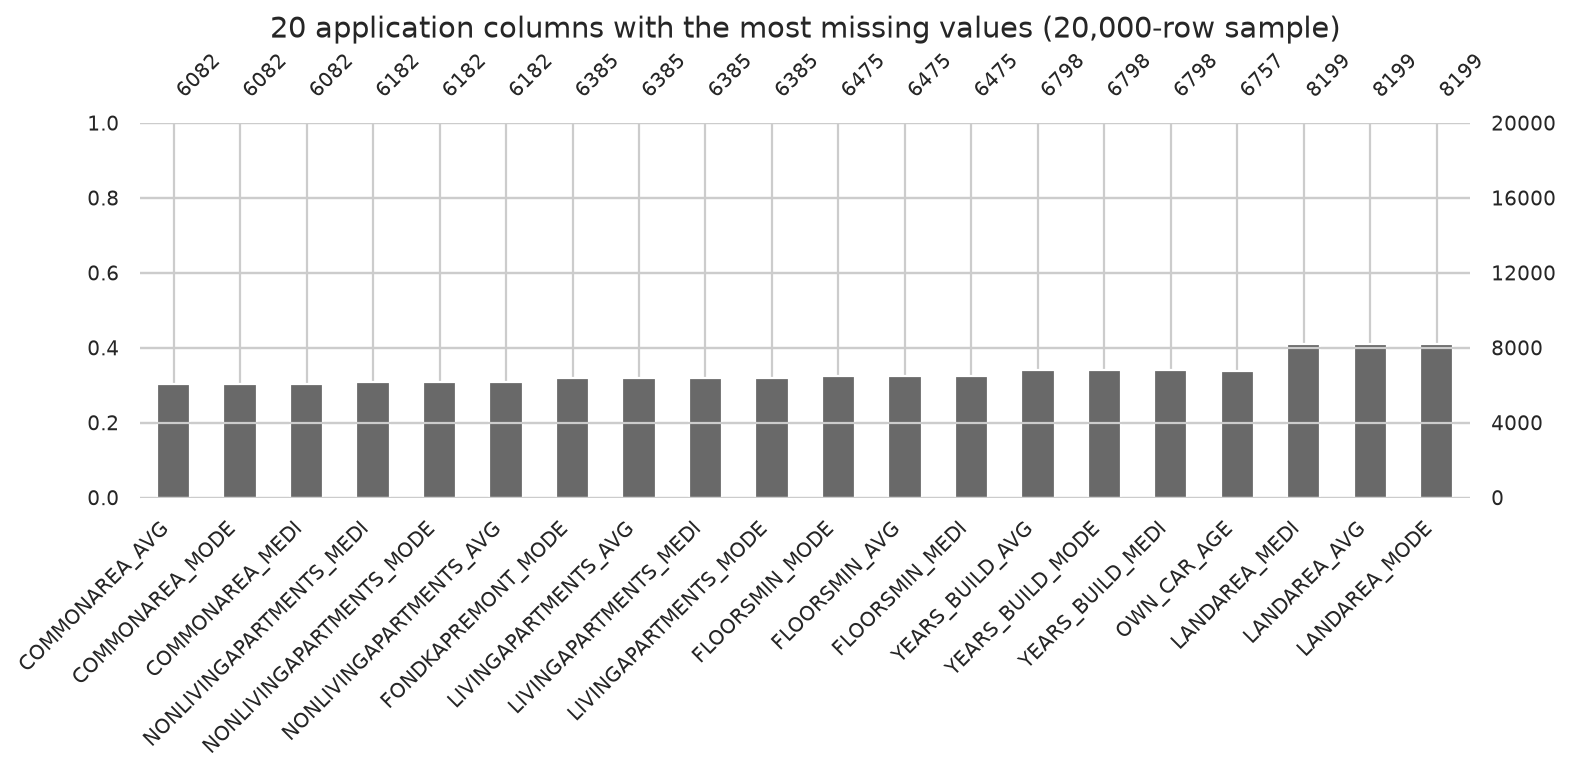

In [4]:
key_cols = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS",
]
display(application[key_cols].describe().T.round(2))

missing_rate = application.isna().mean().sort_values(ascending=False)
missing_rate = missing_rate[missing_rate > 0]
print("Columns with missing values:", len(missing_rate), "/", application.shape[1])
display(missing_rate.head(15).rename("missing rate").to_frame().style.format("{:.1%}"))

plot_cols = missing_rate.head(20).index.tolist()
msno.bar(application[plot_cols].sample(20000, random_state=RANDOM_STATE), figsize=(10, 5), fontsize=9)
plt.title("20 application columns with the most missing values (20,000-row sample)")
plt.tight_layout()
plt.show()


DAYS_EMPLOYED = 365243: 55,374 rows (18.01%)
Mean TARGET: anomaly group 5.400%, remaining 8.660%


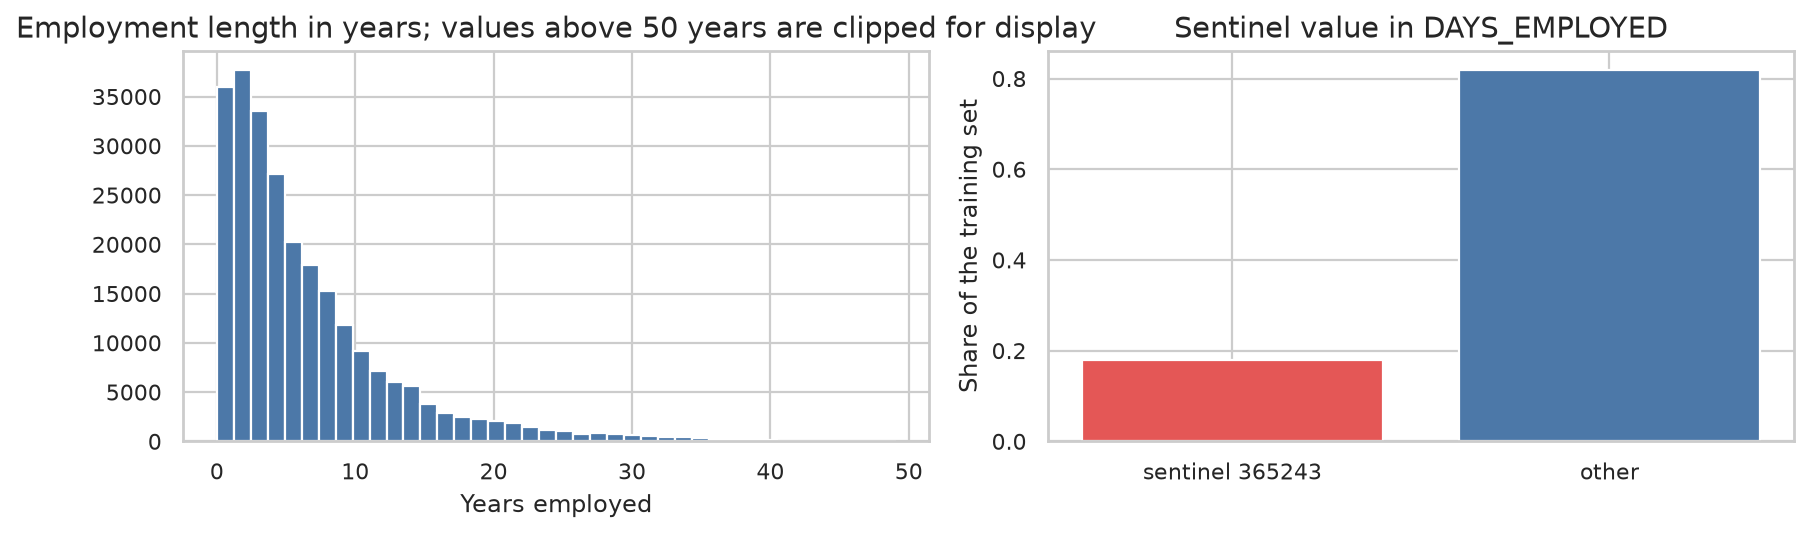

Building _AVG column count: 14 ; median missing rate among them: 56.8%


In [5]:
anom = application["DAYS_EMPLOYED"] == 365243
print("DAYS_EMPLOYED = 365243: {:,} rows ({:.2%})".format(anom.sum(), anom.mean()))
print("Mean TARGET: anomaly group {:.3%}, remaining {:.3%}".format(
    application.loc[anom, "TARGET"].mean(),
    application.loc[~anom, "TARGET"].mean(),
))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
years = (-application.loc[~anom, "DAYS_EMPLOYED"]) / 365.25
axes[0].hist(years.clip(0, 50), bins=40, color="#4C78A8")
axes[0].set_title("Employment length in years; values above 50 years are clipped for display")
axes[0].set_xlabel("Years employed")
axes[1].bar(["sentinel 365243", "other"], [anom.mean(), 1 - anom.mean()], color=["#E45756", "#4C78A8"])
axes[1].set_ylabel("Share of the training set")
axes[1].set_title("Sentinel value in DAYS_EMPLOYED")
plt.tight_layout()
plt.show()

building_avg = [c for c in application.columns if c.endswith("_AVG")]
print("Building _AVG column count:", len(building_avg), "; median missing rate among them: {:.1%}".format(
    application[building_avg].isna().mean().median()
))


`DAYS_EMPLOYED = 365243` is about 1,000 years and marks unemployed or retired applicants. It is set to missing for modeling, and `DAYS_EMPLOYED_ANOM` is kept. Building mean, mode, and median columns largely repeat one another, so only `TOTALAREA_MODE` is kept. A missing-count feature records how complete the housing information is.


### Relationship with default


12 columns with the strongest absolute correlation with TARGET:


,correlation with TARGET
EXT_SOURCE_MEAN,-0.222
EXT_SOURCE_2_3,-0.199
EXT_SOURCE_MAX,-0.197
EXT_SOURCE_PROD,-0.189
EXT_SOURCE_1_3,-0.188
EXT_SOURCE_MIN,-0.185
EXT_SOURCE_3,-0.179
EXT_SOURCE_1_2,-0.176
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155


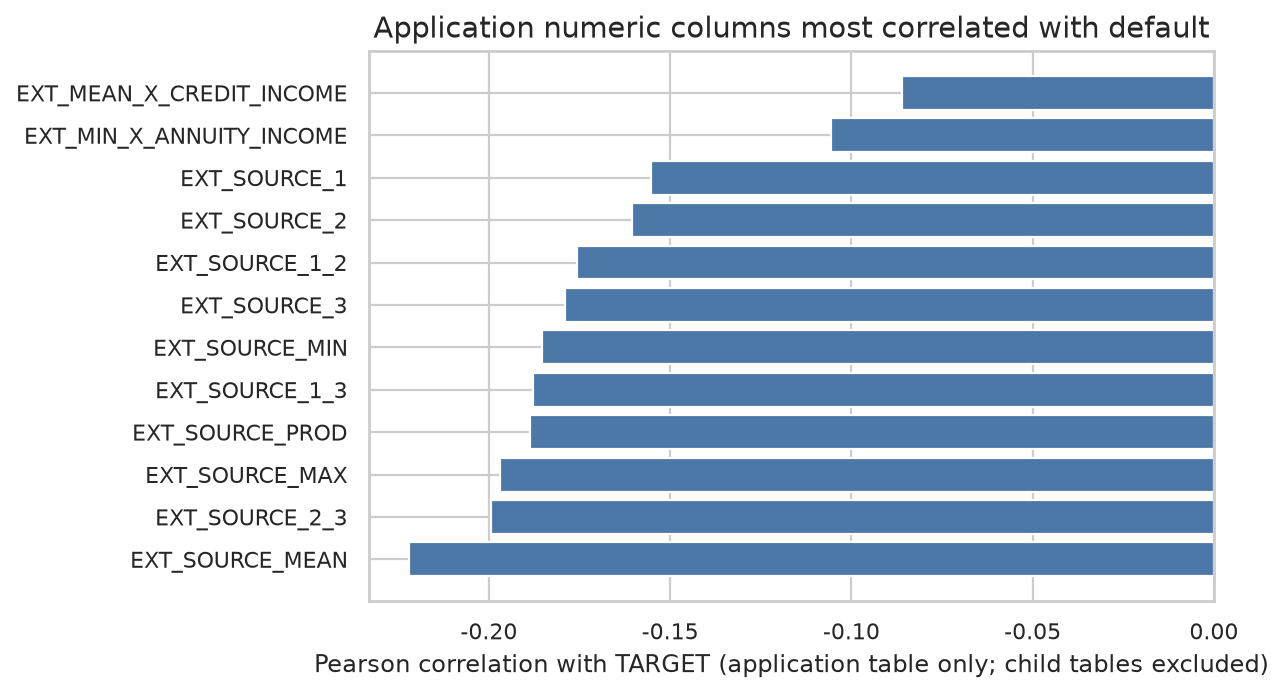

In [6]:
def engineer_application(df):
    # Deterministic cleaning of the application table. TARGET is unused, so the same steps apply to train and test.
    df = df.copy()
    df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(np.int8)
    df.loc[df["DAYS_EMPLOYED_ANOM"] == 1, "DAYS_EMPLOYED"] = np.nan
    df["AGE_YEARS"] = (-df["DAYS_BIRTH"]) / 365.25
    df["EMPLOYED_YEARS"] = (-df["DAYS_EMPLOYED"]) / 365.25
    for src, dst in [
        ("DAYS_REGISTRATION", "REGISTRATION_YEARS"),
        ("DAYS_ID_PUBLISH", "ID_PUBLISH_YEARS"),
        ("DAYS_LAST_PHONE_CHANGE", "PHONE_CHANGE_YEARS"),
    ]:
        df[dst] = (-df[src]) / 365.25

    income = df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    annuity = df["AMT_ANNUITY"].replace(0, np.nan)
    goods = df["AMT_GOODS_PRICE"].replace(0, np.nan)
    family = df["CNT_FAM_MEMBERS"].replace(0, np.nan)
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / income
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / income
    df["CREDIT_TERM"] = df["AMT_CREDIT"] / annuity
    df["CREDIT_GOODS_RATIO"] = df["AMT_CREDIT"] / goods
    df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / family

    ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_SOURCE_MEAN"] = df[ext].mean(axis=1)
    df["EXT_SOURCE_MIN"] = df[ext].min(axis=1)
    df["EXT_SOURCE_MAX"] = df[ext].max(axis=1)
    df["EXT_SOURCE_STD"] = df[ext].std(axis=1)
    df["EXT_SOURCE_MISSING"] = df[ext].isna().sum(axis=1).astype(np.int8)
    df["EXT_SOURCE_1_2"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"]
    df["EXT_SOURCE_1_3"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_3"]
    df["EXT_SOURCE_2_3"] = df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    df["EXT_SOURCE_PROD"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    df["EXT_MEAN_X_CREDIT_INCOME"] = df["EXT_SOURCE_MEAN"] * df["CREDIT_INCOME_RATIO"]
    df["EXT_MIN_X_ANNUITY_INCOME"] = df["EXT_SOURCE_MIN"] * df["ANNUITY_INCOME_RATIO"]

    avg_cols = [c for c in df.columns if c.endswith("_AVG")]
    df["BUILDING_MISSING"] = df[avg_cols].isna().sum(axis=1).astype(np.int16)
    doc_cols = [c for c in df.columns if c.startswith("FLAG_DOCUMENT_")]
    df["DOCUMENT_COUNT"] = df[doc_cols].sum(axis=1).astype(np.int16)
    req_cols = [c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU_")]
    df["BUREAU_ENQUIRY_SUM"] = df[req_cols].sum(axis=1)
    addr = ["REG_CITY_NOT_LIVE_CITY", "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY"]
    df["ADDR_MISMATCH"] = df[addr].sum(axis=1).astype(np.int8)
    for col in ["FLAG_OWN_CAR", "FLAG_OWN_REALTY"]:
        if not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = (df[col].astype(str) == "Y").astype(np.int8)
    df["CONTRACT_CASH"] = (df["NAME_CONTRACT_TYPE"].astype(str) == "Cash loans").astype(np.int8)

    building = [
        c for c in df.columns
        if c.endswith(("_AVG", "_MODE", "_MEDI")) and c != "TOTALAREA_MODE"
    ]
    drop_cols = building + doc_cols + [
        "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
        "DAYS_LAST_PHONE_CHANGE", "WEEKDAY_APPR_PROCESS_START", "NAME_TYPE_SUITE",
        "FLAG_MOBIL", "FLAG_CONT_MOBILE",
    ]
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
    return df


eda = engineer_application(application)
num_corr = eda.select_dtypes(include=[np.number]).corr(numeric_only=True)["TARGET"].drop("TARGET")
num_corr = num_corr.reindex(num_corr.abs().sort_values(ascending=False).index)
print("12 columns with the strongest absolute correlation with TARGET:")
display(num_corr.head(12).rename("correlation with TARGET").to_frame().round(3))

top = num_corr.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#E45756" if v > 0 else "#4C78A8" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.set_xlabel("Pearson correlation with TARGET (application table only; child tables excluded)")
ax.set_title("Application numeric columns most correlated with default")
plt.tight_layout()
plt.show()


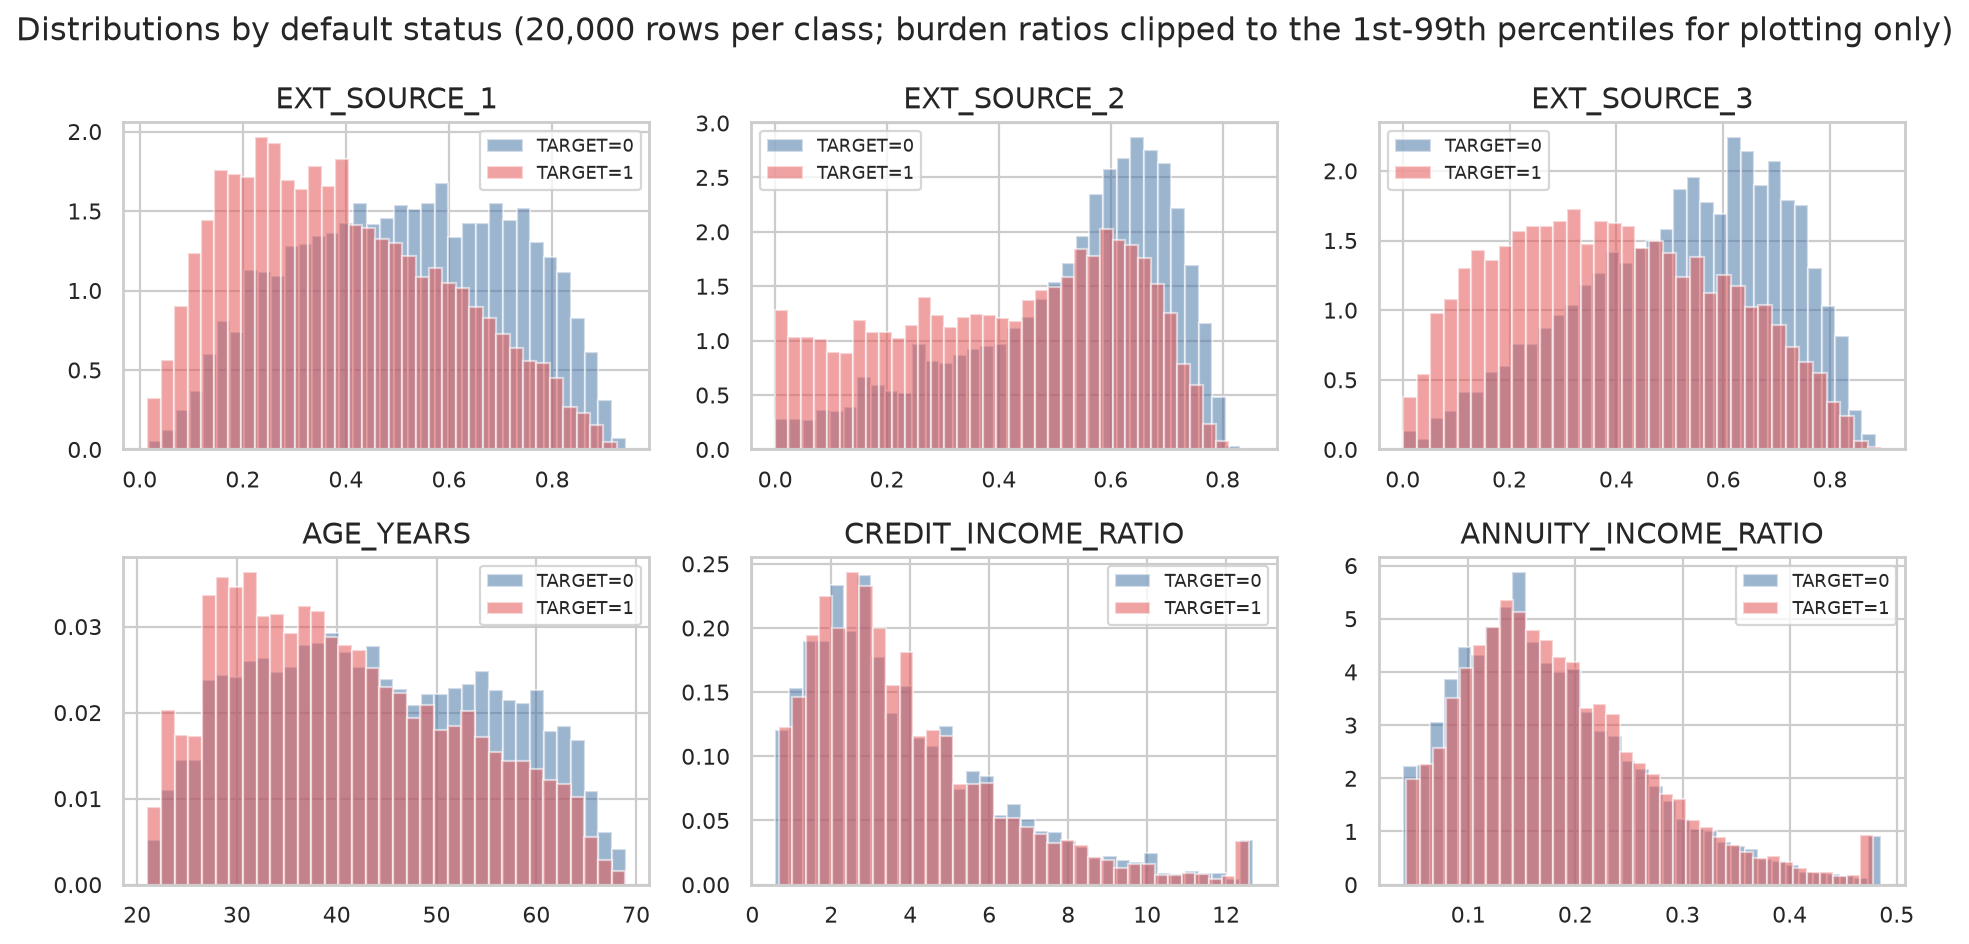

So far, implausible values have only been inspected. They have not been written back to the modeling table.


In [7]:
plot_features = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "AGE_YEARS", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
]
sample = eda.groupby("TARGET", group_keys=False).sample(20000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), plot_features):
    for label, color in [(0, "#4C78A8"), (1, "#E45756")]:
        values = sample.loc[sample["TARGET"] == label, col].dropna()
        if col in ("CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO"):
            lo, hi = values.quantile([0.01, 0.99])
            values = values.clip(lo, hi)
        ax.hist(values, bins=35, density=True, alpha=0.55, color=color, label="TARGET={}".format(label))
    ax.set_title(col)
    ax.legend(fontsize=8)
fig.suptitle("Distributions by default status (20,000 rows per class; burden ratios clipped to the 1st-99th percentiles for plotting only)")
plt.tight_layout()
plt.show()
del sample
gc.collect()
print("So far, implausible values have only been inspected. They have not been written back to the modeling table.")


Higher external scores go with fewer defaults, and older applicants default less often. Credit-to-income and annuity-to-income describe repayment burden. Each class contributes 20,000 rows to the distribution plots. Burden ratios are clipped to the 1st and 99th percentiles for plotting only.


## Data processing


### Multi-table aggregation

One application maps to many loans and many installment records, so those rows are aggregated to `SK_ID_CURR` first. Aggregation does not use `TARGET`.

Previous applications are summarized separately for approved and refused cases, including amounts and the granted-to-requested ratio, and the most recent application is kept. Monthly bureau status keeps the share of each status and the number of months since the latest delinquency. The same statistic is computed on the full history and on the most recent 6 months (or 12 months), and their difference is stored. Days late are `DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT`; a positive value means the payment arrived later. Tree models keep values up to 720 days, while the sequence model uses a tighter clip. Payments with no recorded date are counted separately in the unpaid rate.


In [8]:
FEATURE_PATH = OUTPUT_DIR / "features.parquet"
SEQ_PATH = OUTPUT_DIR / "sequences.npz"


def _mode_from_counts(counts, col, out_name):
    if counts is None or len(counts) == 0:
        return pd.Series(dtype="object", name=out_name)
    total = counts.groupby(["SK_ID_CURR", col], observed=True)["n"].sum().reset_index()
    total = total.sort_values(["SK_ID_CURR", "n"], ascending=[True, False])
    top = total.drop_duplicates("SK_ID_CURR").set_index("SK_ID_CURR")[col]
    top.name = out_name
    return top


def align_sum(parts, index, fill=0.0):
    series = sum_parts(parts)
    if len(series) == 0:
        return pd.Series(fill, index=index, dtype="float64")
    return series.reindex(index).fillna(fill)


def align_ext(parts, index, how="max"):
    series = extremum_parts(parts, how=how)
    if len(series) == 0:
        return pd.Series(np.nan, index=index, dtype="float64")
    return series.reindex(index)


def aggregate_bureau():
    usecols = [
        "SK_ID_CURR", "CREDIT_ACTIVE", "DAYS_CREDIT", "CREDIT_DAY_OVERDUE",
        "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_OVERDUE",
        "CNT_CREDIT_PROLONG", "CREDIT_TYPE",
    ]
    n_parts, recent_parts = [], []
    active_parts, closed_parts, bad_parts = [], [], []
    credit_sum, debt_sum, overdue_sum, prolong_sum = [], [], [], []
    overdue_max, days_max, type_parts = [], [], []
    days_sum, overdue_days_sum, active_debt = [], [], []
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "bureau.csv", usecols=usecols, chunksize=500_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_CURR"].astype(np.int64)
        grouped = chunk.groupby("SK_ID_CURR")
        n_parts.append(grouped.size())
        recent_parts.append(chunk.loc[chunk["DAYS_CREDIT"] >= -365].groupby("SK_ID_CURR").size())
        active_parts.append(chunk.loc[chunk["CREDIT_ACTIVE"] == "Active"].groupby("SK_ID_CURR").size())
        closed_parts.append(chunk.loc[chunk["CREDIT_ACTIVE"] == "Closed"].groupby("SK_ID_CURR").size())
        bad_parts.append(chunk.loc[chunk["CREDIT_ACTIVE"].isin(["Sold", "Bad debt"])].groupby("SK_ID_CURR").size())
        credit_sum.append(grouped["AMT_CREDIT_SUM"].sum(min_count=1))
        debt_sum.append(grouped["AMT_CREDIT_SUM_DEBT"].sum(min_count=1))
        overdue_sum.append(grouped["AMT_CREDIT_SUM_OVERDUE"].sum(min_count=1))
        prolong_sum.append(grouped["CNT_CREDIT_PROLONG"].sum(min_count=1))
        overdue_max.append(grouped["CREDIT_DAY_OVERDUE"].max())
        days_max.append(grouped["DAYS_CREDIT"].max())
        days_sum.append(grouped["DAYS_CREDIT"].sum(min_count=1))
        overdue_days_sum.append(grouped["CREDIT_DAY_OVERDUE"].sum(min_count=1))
        active_mask = chunk["CREDIT_ACTIVE"] == "Active"
        if active_mask.any():
            active_debt.append(chunk.loc[active_mask].groupby("SK_ID_CURR")["AMT_CREDIT_SUM_DEBT"].sum(min_count=1))
        type_parts.append(
            chunk.groupby(["SK_ID_CURR", "CREDIT_TYPE"], observed=True).size().rename("n").reset_index()
        )
    print("bureau rows: {:,}".format(rows))
    bureau_n = sum_parts(n_parts)
    out = pd.DataFrame(index=bureau_n.index)
    out["bureau_n"] = bureau_n
    out["bureau_recent12_n"] = align_sum(recent_parts, bureau_n.index)
    out["bureau_active_n"] = align_sum(active_parts, bureau_n.index)
    out["bureau_closed_n"] = align_sum(closed_parts, bureau_n.index)
    out["bureau_bad_n"] = align_sum(bad_parts, bureau_n.index)
    out["bureau_credit_sum"] = align_sum(credit_sum, bureau_n.index, fill=np.nan)
    out["bureau_debt_sum"] = align_sum(debt_sum, bureau_n.index, fill=np.nan)
    out["bureau_overdue_sum"] = align_sum(overdue_sum, bureau_n.index, fill=np.nan)
    out["bureau_prolong_sum"] = align_sum(prolong_sum, bureau_n.index, fill=np.nan)
    out["bureau_overdue_days_max"] = align_ext(overdue_max, bureau_n.index, "max")
    out["bureau_days_credit_max"] = align_ext(days_max, bureau_n.index, "max")
    out["bureau_days_credit_mean"] = align_sum(days_sum, bureau_n.index, fill=np.nan) / bureau_n.replace(0, np.nan)
    out["bureau_overdue_days_mean"] = align_sum(overdue_days_sum, bureau_n.index, fill=np.nan) / bureau_n.replace(0, np.nan)
    out["bureau_active_debt_sum"] = align_sum(active_debt, bureau_n.index, fill=np.nan)
    out["bureau_credit_mean"] = out["bureau_credit_sum"] / bureau_n.replace(0, np.nan)
    out["bureau_debt_ratio"] = out["bureau_debt_sum"] / out["bureau_credit_sum"].replace(0, np.nan)
    out["bureau_active_frac"] = out["bureau_active_n"] / out["bureau_n"].replace(0, np.nan)
    out["bureau_credit_type_mode"] = _mode_from_counts(pd.concat(type_parts, ignore_index=True), "CREDIT_TYPE", "bureau_credit_type_mode")
    out.index.name = "SK_ID_CURR"
    return out.reset_index()


def build_status_sequence(monthly, id_to_row, n_rows, timesteps=24):
    seq = np.zeros((n_rows, timesteps), dtype=np.int8)
    sub = monthly[(monthly["MONTHS_BALANCE"] <= 0) & (monthly["MONTHS_BALANCE"] >= -(timesteps - 1))].copy()
    sub = sub[sub["code"].notna()]
    sub["slot"] = (-sub["MONTHS_BALANCE"]).astype(np.int16)
    sub = sub[(sub["slot"] >= 0) & (sub["slot"] < timesteps)]
    sub = sub.groupby(["SK_ID_CURR", "slot"], as_index=False)["code"].max()
    row = id_to_row.reindex(sub["SK_ID_CURR"]).to_numpy()
    ok = ~pd.isna(row)
    seq[row[ok].astype(np.int32), sub.loc[ok, "slot"].to_numpy(dtype=np.int32)] = (
        sub.loc[ok, "code"].to_numpy(dtype=np.int16) + 1
    ).astype(np.int8)
    return seq


def aggregate_bureau_balance(id_to_row, n_rows):
    bureau_ids = pd.read_csv(DATA_DIR / "bureau.csv", usecols=["SK_ID_BUREAU", "SK_ID_CURR"])
    print("SK_ID_BUREAU unique before aggregation:", bureau_ids["SK_ID_BUREAU"].is_unique)
    bureau_ids = bureau_ids.drop_duplicates("SK_ID_BUREAU")
    mapper = pd.Series(
        bureau_ids["SK_ID_CURR"].astype(np.int64).to_numpy(),
        index=bureau_ids["SK_ID_BUREAU"].astype(np.int64).to_numpy(),
    )
    del bureau_ids
    status_map = {"C": 0.0, "X": np.nan, "0": 0.0, "1": 1.0, "2": 2.0, "3": 3.0, "4": 4.0, "5": 5.0}
    acc = None
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "bureau_balance.csv", chunksize=2_000_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_BUREAU"].astype(np.int64).map(mapper)
        chunk = chunk.dropna(subset=["SK_ID_CURR"])
        chunk["code"] = chunk["STATUS"].astype(str).str.strip().map(status_map)
        grouped = chunk.groupby(["SK_ID_CURR", "MONTHS_BALANCE"], sort=False)["code"].max()
        acc = grouped if acc is None else pd.concat([acc, grouped]).groupby(level=[0, 1]).max()
        print("  bureau_balance read {:,} rows, client-months {:.2f} million".format(rows, len(acc) / 1e6))
    print("bureau_balance rows: {:,}".format(rows))
    monthly = acc.rename("code").reset_index()
    del acc, mapper
    gc.collect()
    known = monthly[monthly["code"].notna()].copy()
    del monthly
    known["late"] = (known["code"] >= 1).astype(np.int8)
    known["severe"] = (known["code"] >= 5).astype(np.int8)
    grouped = known.groupby("SK_ID_CURR")
    out = pd.DataFrame({
        "bb_months": grouped.size(),
        "bb_late_frac": grouped["late"].mean(),
        "bb_severe_frac": grouped["severe"].mean(),
        "bb_max_code": grouped["code"].max(),
    })
    out["bb_recent6_late_frac"] = known.loc[known["MONTHS_BALANCE"] >= -6].groupby("SK_ID_CURR")["late"].mean()
    out["bb_recent12_late_frac"] = known.loc[known["MONTHS_BALANCE"] >= -12].groupby("SK_ID_CURR")["late"].mean()
    last_idx = known.groupby("SK_ID_CURR")["MONTHS_BALANCE"].idxmax()
    out["bb_last_code"] = known.loc[last_idx].set_index("SK_ID_CURR")["code"]
    months = out["bb_months"].replace(0, np.nan)
    for code in range(6):
        cnt = known.loc[known["code"] == code].groupby("SK_ID_CURR").size()
        out["bb_status_%d_frac" % code] = cnt.reindex(out.index).fillna(0) / months
    late_last = known.loc[known["late"] == 1].groupby("SK_ID_CURR")["MONTHS_BALANCE"].max()
    out["bb_months_since_late"] = (-late_last).reindex(out.index)
    seq = build_status_sequence(known, id_to_row, n_rows)
    out.index.name = "SK_ID_CURR"
    return out.reset_index(), seq


def aggregate_previous():
    usecols = [
        "SK_ID_CURR", "NAME_CONTRACT_STATUS", "CODE_REJECT_REASON", "PRODUCT_COMBINATION",
        "NAME_YIELD_GROUP", "DAYS_DECISION", "AMT_APPLICATION", "AMT_CREDIT", "AMT_ANNUITY",
    ]
    n_parts, approved, refused, canceled, recent = [], [], [], [], []
    days_max, ratio_sum, ratio_n, ann_sum, ann_n = [], [], [], [], []
    appr_credit_sum, appr_credit_n = [], []
    ref_credit_sum, ref_credit_n = [], []
    appr_ratio_sum, appr_ratio_n = [], []
    ref_ratio_sum, ref_ratio_n = [], []
    recent_refused, last_parts = [], []
    mode_parts = {col: [] for col in ["NAME_CONTRACT_STATUS", "CODE_REJECT_REASON", "PRODUCT_COMBINATION", "NAME_YIELD_GROUP"]}
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "previous_application.csv", usecols=usecols, chunksize=500_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_CURR"].astype(np.int64)
        n_parts.append(chunk.groupby("SK_ID_CURR").size())
        approved.append(chunk.loc[chunk["NAME_CONTRACT_STATUS"] == "Approved"].groupby("SK_ID_CURR").size())
        refused.append(chunk.loc[chunk["NAME_CONTRACT_STATUS"] == "Refused"].groupby("SK_ID_CURR").size())
        canceled.append(chunk.loc[chunk["NAME_CONTRACT_STATUS"] == "Canceled"].groupby("SK_ID_CURR").size())
        recent.append(chunk.loc[chunk["DAYS_DECISION"] >= -365].groupby("SK_ID_CURR").size())
        days_max.append(chunk.groupby("SK_ID_CURR")["DAYS_DECISION"].max())
        ratio = chunk["AMT_CREDIT"] / chunk["AMT_APPLICATION"].where(chunk["AMT_APPLICATION"] > 0)
        ratio_sum.append(ratio.groupby(chunk["SK_ID_CURR"]).sum(min_count=1))
        ratio_n.append(ratio.groupby(chunk["SK_ID_CURR"]).count())
        ann_sum.append(chunk.groupby("SK_ID_CURR")["AMT_ANNUITY"].sum(min_count=1))
        ann_n.append(chunk.groupby("SK_ID_CURR")["AMT_ANNUITY"].count())
        for col in mode_parts:
            mode_parts[col].append(chunk.groupby(["SK_ID_CURR", col], observed=True).size().rename("n").reset_index())
        appr = chunk["NAME_CONTRACT_STATUS"] == "Approved"
        refu = chunk["NAME_CONTRACT_STATUS"] == "Refused"
        if appr.any():
            appr_credit_sum.append(chunk.loc[appr].groupby("SK_ID_CURR")["AMT_CREDIT"].sum(min_count=1))
            appr_credit_n.append(chunk.loc[appr].groupby("SK_ID_CURR")["AMT_CREDIT"].count())
            appr_ratio_sum.append(ratio.loc[appr].groupby(chunk.loc[appr, "SK_ID_CURR"]).sum(min_count=1))
            appr_ratio_n.append(ratio.loc[appr].groupby(chunk.loc[appr, "SK_ID_CURR"]).count())
        if refu.any():
            ref_credit_sum.append(chunk.loc[refu].groupby("SK_ID_CURR")["AMT_CREDIT"].sum(min_count=1))
            ref_credit_n.append(chunk.loc[refu].groupby("SK_ID_CURR")["AMT_CREDIT"].count())
            ref_ratio_sum.append(ratio.loc[refu].groupby(chunk.loc[refu, "SK_ID_CURR"]).sum(min_count=1))
            ref_ratio_n.append(ratio.loc[refu].groupby(chunk.loc[refu, "SK_ID_CURR"]).count())
            recent_refused.append(chunk.loc[refu & (chunk["DAYS_DECISION"] >= -365)].groupby("SK_ID_CURR").size())
        last_parts.append(chunk[["SK_ID_CURR", "DAYS_DECISION", "AMT_CREDIT", "AMT_APPLICATION", "NAME_CONTRACT_STATUS"]])
    print("previous_application rows: {:,}".format(rows))
    prev_n = sum_parts(n_parts)
    out = pd.DataFrame(index=prev_n.index)
    out["prev_n"] = prev_n
    out["prev_approved_n"] = align_sum(approved, prev_n.index)
    out["prev_refused_n"] = align_sum(refused, prev_n.index)
    out["prev_canceled_n"] = align_sum(canceled, prev_n.index)
    out["prev_recent12_n"] = align_sum(recent, prev_n.index)
    out["prev_days_decision_max"] = align_ext(days_max, prev_n.index, "max")
    out["prev_credit_app_ratio"] = align_sum(ratio_sum, prev_n.index, fill=np.nan) / align_sum(ratio_n, prev_n.index).replace(0, np.nan)
    out["prev_annuity_mean"] = align_sum(ann_sum, prev_n.index, fill=np.nan) / align_sum(ann_n, prev_n.index).replace(0, np.nan)
    out["prev_approved_frac"] = out["prev_approved_n"] / out["prev_n"].replace(0, np.nan)
    out["prev_refused_frac"] = out["prev_refused_n"] / out["prev_n"].replace(0, np.nan)
    out["prev_status_mode"] = _mode_from_counts(pd.concat(mode_parts["NAME_CONTRACT_STATUS"], ignore_index=True), "NAME_CONTRACT_STATUS", "prev_status_mode")
    out["prev_reject_mode"] = _mode_from_counts(pd.concat(mode_parts["CODE_REJECT_REASON"], ignore_index=True), "CODE_REJECT_REASON", "prev_reject_mode")
    out["prev_product_mode"] = _mode_from_counts(pd.concat(mode_parts["PRODUCT_COMBINATION"], ignore_index=True), "PRODUCT_COMBINATION", "prev_product_mode")
    out["prev_yield_mode"] = _mode_from_counts(pd.concat(mode_parts["NAME_YIELD_GROUP"], ignore_index=True), "NAME_YIELD_GROUP", "prev_yield_mode")
    out["prev_appr_credit_mean"] = align_sum(appr_credit_sum, prev_n.index, fill=np.nan) / align_sum(appr_credit_n, prev_n.index).replace(0, np.nan)
    out["prev_ref_credit_mean"] = align_sum(ref_credit_sum, prev_n.index, fill=np.nan) / align_sum(ref_credit_n, prev_n.index).replace(0, np.nan)
    out["prev_appr_ratio"] = align_sum(appr_ratio_sum, prev_n.index, fill=np.nan) / align_sum(appr_ratio_n, prev_n.index).replace(0, np.nan)
    out["prev_ref_ratio"] = align_sum(ref_ratio_sum, prev_n.index, fill=np.nan) / align_sum(ref_ratio_n, prev_n.index).replace(0, np.nan)
    out["prev_refused_recent12_n"] = align_sum(recent_refused, prev_n.index)
    out["prev_refused_frac_recent12"] = out["prev_refused_recent12_n"] / out["prev_recent12_n"].replace(0, np.nan)
    out["prev_refused_trend"] = out["prev_refused_frac_recent12"] - out["prev_refused_frac"]
    last = pd.concat(last_parts, ignore_index=True)
    last = last.sort_values(["SK_ID_CURR", "DAYS_DECISION"]).groupby("SK_ID_CURR", as_index=False).tail(1)
    last = last.set_index("SK_ID_CURR")
    out["prev_last_days"] = last["DAYS_DECISION"]
    out["prev_last_credit"] = last["AMT_CREDIT"]
    out["prev_last_ratio"] = last["AMT_CREDIT"] / last["AMT_APPLICATION"].replace(0, np.nan)
    out["prev_last_refused"] = (last["NAME_CONTRACT_STATUS"] == "Refused").astype(np.float64)
    out.index.name = "SK_ID_CURR"
    return out.reset_index()


def aggregate_pos():
    usecols = ["SK_ID_CURR", "MONTHS_BALANCE", "CNT_INSTALMENT_FUTURE", "NAME_CONTRACT_STATUS", "SK_DPD"]
    n_parts, dpd_sum, dpd_n, dpd_max = [], [], [], []
    completed, active, r6_sum, r6_n = [], [], [], []
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "POS_CASH_balance.csv", usecols=usecols, chunksize=1_000_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_CURR"].astype(np.int64)
        n_parts.append(chunk.groupby("SK_ID_CURR").size())
        dpd_sum.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].sum(min_count=1))
        dpd_n.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].count())
        dpd_max.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].max())
        completed.append(chunk.loc[chunk["CNT_INSTALMENT_FUTURE"] == 0].groupby("SK_ID_CURR").size())
        active.append(chunk.loc[chunk["NAME_CONTRACT_STATUS"] == "Active"].groupby("SK_ID_CURR").size())
        recent = chunk.loc[chunk["MONTHS_BALANCE"] >= -6]
        r6_sum.append(recent.groupby("SK_ID_CURR")["SK_DPD"].sum(min_count=1))
        r6_n.append(recent.groupby("SK_ID_CURR")["SK_DPD"].count())
    print("POS_CASH_balance rows: {:,}".format(rows))
    pos_n = sum_parts(n_parts)
    out = pd.DataFrame(index=pos_n.index)
    out["pos_n"] = pos_n
    out["pos_dpd_mean"] = align_sum(dpd_sum, pos_n.index, fill=np.nan) / align_sum(dpd_n, pos_n.index).replace(0, np.nan)
    out["pos_dpd_max"] = align_ext(dpd_max, pos_n.index, "max")
    out["pos_completed_frac"] = align_sum(completed, pos_n.index) / pos_n.replace(0, np.nan)
    out["pos_active_frac"] = align_sum(active, pos_n.index) / pos_n.replace(0, np.nan)
    out["pos_recent6_dpd_mean"] = align_sum(r6_sum, pos_n.index, fill=np.nan) / align_sum(r6_n, pos_n.index).replace(0, np.nan)
    out.index.name = "SK_ID_CURR"
    return out.reset_index()


def aggregate_credit_card():
    usecols = [
        "SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL",
        "AMT_PAYMENT_CURRENT", "AMT_INST_MIN_REGULARITY", "SK_DPD",
    ]
    n_parts, util_sum, util_n, util_max = [], [], [], []
    pay_sum, pay_n, dpd_sum, dpd_n, dpd_max = [], [], [], [], []
    r6_sum, r6_n = [], []
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "credit_card_balance.csv", usecols=usecols, chunksize=1_000_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_CURR"].astype(np.int64)
        util = (chunk["AMT_BALANCE"] / chunk["AMT_CREDIT_LIMIT_ACTUAL"].where(chunk["AMT_CREDIT_LIMIT_ACTUAL"] > 0)).clip(0, 5)
        pay = (chunk["AMT_PAYMENT_CURRENT"] / chunk["AMT_INST_MIN_REGULARITY"].where(chunk["AMT_INST_MIN_REGULARITY"] > 0)).clip(0, 5)
        n_parts.append(chunk.groupby("SK_ID_CURR").size())
        util_sum.append(util.groupby(chunk["SK_ID_CURR"]).sum(min_count=1))
        util_n.append(util.groupby(chunk["SK_ID_CURR"]).count())
        util_max.append(util.groupby(chunk["SK_ID_CURR"]).max())
        pay_sum.append(pay.groupby(chunk["SK_ID_CURR"]).sum(min_count=1))
        pay_n.append(pay.groupby(chunk["SK_ID_CURR"]).count())
        dpd_sum.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].sum(min_count=1))
        dpd_n.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].count())
        dpd_max.append(chunk.groupby("SK_ID_CURR")["SK_DPD"].max())
        recent = chunk["MONTHS_BALANCE"] >= -6
        r6_sum.append(util.loc[recent].groupby(chunk.loc[recent, "SK_ID_CURR"]).sum(min_count=1))
        r6_n.append(util.loc[recent].groupby(chunk.loc[recent, "SK_ID_CURR"]).count())
    print("credit_card_balance rows: {:,}".format(rows))
    cc_n = sum_parts(n_parts)
    out = pd.DataFrame(index=cc_n.index)
    out["cc_n"] = cc_n
    out["cc_util_mean"] = align_sum(util_sum, cc_n.index, fill=np.nan) / align_sum(util_n, cc_n.index).replace(0, np.nan)
    out["cc_util_max"] = align_ext(util_max, cc_n.index, "max")
    out["cc_pay_ratio_mean"] = align_sum(pay_sum, cc_n.index, fill=np.nan) / align_sum(pay_n, cc_n.index).replace(0, np.nan)
    out["cc_dpd_mean"] = align_sum(dpd_sum, cc_n.index, fill=np.nan) / align_sum(dpd_n, cc_n.index).replace(0, np.nan)
    out["cc_dpd_max"] = align_ext(dpd_max, cc_n.index, "max")
    out["cc_recent6_util_mean"] = align_sum(r6_sum, cc_n.index, fill=np.nan) / align_sum(r6_n, cc_n.index).replace(0, np.nan)
    out.index.name = "SK_ID_CURR"
    return out.reset_index()


def build_inst_sequence(ids, days, late, ratio, id_to_row, n_rows, timesteps=24):
    ok = ~np.isnan(days)
    ids, days, late, ratio = ids[ok], days[ok], late[ok], ratio[ok]
    order = np.lexsort((-days, ids))
    ids, late, ratio = ids[order], late[order], ratio[order]
    new_group = np.empty(len(ids), dtype=bool)
    new_group[0] = True
    new_group[1:] = ids[1:] != ids[:-1]
    starts = np.maximum.accumulate(np.where(new_group, np.arange(len(ids)), 0))
    rank = np.arange(len(ids)) - starts
    keep = rank < timesteps
    seq = np.full((n_rows, timesteps, 3), np.nan, dtype=np.float32)
    seq[:, :, 2] = 0
    row = id_to_row.reindex(ids[keep]).to_numpy()
    valid = ~pd.isna(row)
    row = row[valid].astype(np.int32)
    slot = rank[keep][valid].astype(np.int32)
    seq[row, slot, 0] = late[keep][valid]
    seq[row, slot, 1] = ratio[keep][valid]
    seq[row, slot, 2] = 1
    return seq


def aggregate_installments(id_to_row, n_rows):
    usecols = ["SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"]
    n_parts, late_sum, late_n, late_max, late_event, unpaid = [], [], [], [], [], []
    ratio_sum, ratio_n = [], []
    r6_late_sum, r6_late_n, r6_ratio_sum, r6_ratio_n = [], [], [], []
    r12_n, r12_bad = [], []
    ids_all, days_all, late_all, ratio_all = [], [], [], []
    late_tree_all, ratio_tree_all = [], []
    rows = 0
    for chunk in pd.read_csv(DATA_DIR / "installments_payments.csv", usecols=usecols, chunksize=1_000_000):
        rows += len(chunk)
        chunk["SK_ID_CURR"] = chunk["SK_ID_CURR"].astype(np.int64)
        late = (chunk["DAYS_ENTRY_PAYMENT"] - chunk["DAYS_INSTALMENT"]).clip(-60, 720)
        unpaid_mask = chunk["DAYS_ENTRY_PAYMENT"].isna() & chunk["AMT_INSTALMENT"].notna()
        ratio = chunk["AMT_PAYMENT"] / chunk["AMT_INSTALMENT"].where(chunk["AMT_INSTALMENT"] > 0)
        ratio = ratio.mask(unpaid_mask, 0).clip(0, 10)
        late_for_seq = late.clip(-90, 180)
        ratio_for_seq = ratio.clip(0, 5)
        n_parts.append(chunk.groupby("SK_ID_CURR").size())
        known = late.notna()
        late_sum.append(late.loc[known].groupby(chunk.loc[known, "SK_ID_CURR"]).sum())
        late_n.append(late.loc[known].groupby(chunk.loc[known, "SK_ID_CURR"]).size())
        late_max.append(late.loc[known].groupby(chunk.loc[known, "SK_ID_CURR"]).max())
        late_event.append(late.loc[late.gt(0)].groupby(chunk.loc[late.gt(0), "SK_ID_CURR"]).size())
        unpaid.append(chunk.loc[unpaid_mask].groupby("SK_ID_CURR").size())
        known_r = ratio.notna()
        ratio_sum.append(ratio.loc[known_r].groupby(chunk.loc[known_r, "SK_ID_CURR"]).sum())
        ratio_n.append(ratio.loc[known_r].groupby(chunk.loc[known_r, "SK_ID_CURR"]).size())
        r6 = chunk["DAYS_INSTALMENT"] >= -180
        r12 = chunk["DAYS_INSTALMENT"] >= -365
        r6_late = r6 & known
        r6_late_sum.append(late.loc[r6_late].groupby(chunk.loc[r6_late, "SK_ID_CURR"]).sum())
        r6_late_n.append(late.loc[r6_late].groupby(chunk.loc[r6_late, "SK_ID_CURR"]).size())
        r6_ratio = r6 & known_r
        r6_ratio_sum.append(ratio.loc[r6_ratio].groupby(chunk.loc[r6_ratio, "SK_ID_CURR"]).sum())
        r6_ratio_n.append(ratio.loc[r6_ratio].groupby(chunk.loc[r6_ratio, "SK_ID_CURR"]).size())
        r12_n.append(chunk.loc[r12].groupby("SK_ID_CURR").size())
        bad = r12 & (late.gt(0) | unpaid_mask)
        r12_bad.append(chunk.loc[bad].groupby("SK_ID_CURR").size())
        ids_all.append(chunk["SK_ID_CURR"].to_numpy(np.int64, copy=True))
        days_all.append(chunk["DAYS_INSTALMENT"].to_numpy(np.float32, copy=True))
        late_all.append(late_for_seq.to_numpy(np.float32, copy=True))
        ratio_all.append(ratio_for_seq.to_numpy(np.float32, copy=True))
        late_tree_all.append(late.to_numpy(np.float32, copy=True))
        ratio_tree_all.append(ratio.to_numpy(np.float32, copy=True))
        if rows % 4_000_000 < 1_000_000:
            print("  installments read {:,}".format(rows))
    print("installments_payments rows: {:,}".format(rows))
    inst_n = sum_parts(n_parts)
    out = pd.DataFrame(index=inst_n.index)
    out["inst_n"] = inst_n
    out["inst_late_mean"] = align_sum(late_sum, inst_n.index, fill=np.nan) / align_sum(late_n, inst_n.index).replace(0, np.nan)
    out["inst_late_max"] = align_ext(late_max, inst_n.index, "max")
    out["inst_late_frac"] = align_sum(late_event, inst_n.index) / inst_n.replace(0, np.nan)
    out["inst_unpaid_frac"] = align_sum(unpaid, inst_n.index) / inst_n.replace(0, np.nan)
    out["inst_payment_ratio_mean"] = align_sum(ratio_sum, inst_n.index, fill=np.nan) / align_sum(ratio_n, inst_n.index).replace(0, np.nan)
    out["inst_recent6_late_mean"] = align_sum(r6_late_sum, inst_n.index, fill=np.nan) / align_sum(r6_late_n, inst_n.index).replace(0, np.nan)
    out["inst_recent6_payment_ratio_mean"] = align_sum(r6_ratio_sum, inst_n.index, fill=np.nan) / align_sum(r6_ratio_n, inst_n.index).replace(0, np.nan)
    out["inst_recent12_late_frac"] = align_sum(r12_bad, inst_n.index) / align_sum(r12_n, inst_n.index).replace(0, np.nan)
    ids_cat = np.concatenate(ids_all)
    days_cat = np.concatenate(days_all)
    order = np.lexsort((-days_cat, ids_cat))
    ids_s = ids_cat[order]
    late_s = np.concatenate(late_tree_all)[order]
    ratio_s = np.concatenate(ratio_tree_all)[order]
    new_group = np.empty(len(ids_s), dtype=bool)
    new_group[0] = True
    new_group[1:] = ids_s[1:] != ids_s[:-1]
    last_pay = pd.DataFrame({"inst_last_late": late_s[new_group], "inst_last_ratio": ratio_s[new_group]}, index=pd.Index(ids_s[new_group], name="SK_ID_CURR"))
    last_pay = last_pay[~last_pay.index.duplicated(keep="first")]
    out["inst_last_late"] = last_pay["inst_last_late"]
    out["inst_last_ratio"] = last_pay["inst_last_ratio"]
    out.index.name = "SK_ID_CURR"
    seq = build_inst_sequence(
        np.concatenate(ids_all), np.concatenate(days_all), np.concatenate(late_all), np.concatenate(ratio_all),
        id_to_row, n_rows,
    )
    return out.reset_index(), seq


def add_derived(features):
    pairs = [
        ("bb_late_trend_6", "bb_recent6_late_frac", "bb_late_frac"),
        ("bb_late_trend_12", "bb_recent12_late_frac", "bb_late_frac"),
        ("pos_dpd_trend_6", "pos_recent6_dpd_mean", "pos_dpd_mean"),
        ("cc_util_trend_6", "cc_recent6_util_mean", "cc_util_mean"),
        ("inst_late_trend_6", "inst_recent6_late_mean", "inst_late_mean"),
        ("inst_pay_trend_6", "inst_recent6_payment_ratio_mean", "inst_payment_ratio_mean"),
    ]
    for name, left, right in pairs:
        if left in features.columns and right in features.columns:
            features[name] = features[left] - features[right]
    return features


def merge_agg(base, agg, count_cols, sum_cols):
    assert agg["SK_ID_CURR"].is_unique
    merged = base.merge(agg, on="SK_ID_CURR", how="left")
    for col in count_cols:
        if col in merged.columns:
            merged[col] = merged[col].fillna(0)
    absent = merged[count_cols[0]].eq(0) if count_cols else None
    if absent is not None:
        for col in sum_cols:
            if col in merged.columns:
                merged.loc[absent, col] = 0
    return merged


if FEATURE_PATH.exists() and SEQ_PATH.exists() and not REBUILD_FEATURES:
    features = pd.read_parquet(FEATURE_PATH)
    saved = np.load(SEQ_PATH)
    status_seq = saved["status"]
    inst_seq = saved["inst"]
    seq_ids = saved["ids"].astype(np.int64)
    assert np.array_equal(features["SK_ID_CURR"].to_numpy(dtype=np.int64), seq_ids)
    print("Loaded cached features:", features.shape)
else:
    del eda
    gc.collect()
    print("Starting aggregation, available memory {:.1f} GB".format(psutil.virtual_memory().available / 1e9))
    train_fe = engineer_application(application)
    test_fe = engineer_application(application_test)
    del application, application_test
    train_fe["SET"] = "train"
    test_fe["SET"] = "test"
    test_fe["TARGET"] = np.nan
    features = pd.concat([train_fe, test_fe], ignore_index=True)
    del train_fe, test_fe
    gc.collect()
    features["SK_ID_CURR"] = features["SK_ID_CURR"].astype(np.int64)
    seq_ids = features["SK_ID_CURR"].to_numpy(dtype=np.int64).copy()
    id_to_row = pd.Series(np.arange(len(seq_ids), dtype=np.int32), index=pd.Index(seq_ids))
    application_columns = [c for c in features.columns]

    t0 = time.perf_counter()
    bureau_agg = aggregate_bureau()
    features = merge_agg(
        features, bureau_agg,
        ["bureau_n", "bureau_recent12_n", "bureau_active_n", "bureau_closed_n", "bureau_bad_n"],
        ["bureau_credit_sum", "bureau_debt_sum", "bureau_overdue_sum", "bureau_prolong_sum", "bureau_active_debt_sum"],
    )
    del bureau_agg
    gc.collect()
    print("bureau merged in {:.1f} min, memory {:.1f} GB".format((time.perf_counter() - t0) / 60, psutil.virtual_memory().available / 1e9))

    t0 = time.perf_counter()
    bb_agg, status_seq = aggregate_bureau_balance(id_to_row, len(features))
    features = merge_agg(features, bb_agg, ["bb_months"], [])
    del bb_agg
    gc.collect()
    print("bureau_balance merged in {:.1f} min".format((time.perf_counter() - t0) / 60))

    t0 = time.perf_counter()
    prev_agg = aggregate_previous()
    features = merge_agg(
        features, prev_agg,
        ["prev_n", "prev_approved_n", "prev_refused_n", "prev_canceled_n", "prev_recent12_n", "prev_refused_recent12_n"],
        [],
    )
    del prev_agg
    gc.collect()
    print("previous merged in {:.1f} min".format((time.perf_counter() - t0) / 60))

    t0 = time.perf_counter()
    pos_agg = aggregate_pos()
    features = merge_agg(features, pos_agg, ["pos_n"], [])
    del pos_agg
    gc.collect()
    print("POS merged in {:.1f} min".format((time.perf_counter() - t0) / 60))

    t0 = time.perf_counter()
    cc_agg = aggregate_credit_card()
    features = merge_agg(features, cc_agg, ["cc_n"], [])
    del cc_agg
    gc.collect()
    print("credit card merged in {:.1f} min".format((time.perf_counter() - t0) / 60))

    t0 = time.perf_counter()
    inst_agg, inst_seq = aggregate_installments(id_to_row, len(features))
    features = merge_agg(features, inst_agg, ["inst_n"], [])
    del inst_agg
    gc.collect()
    print("installments merged in {:.1f} min".format((time.perf_counter() - t0) / 60))

    features = add_derived(features)
    features["NO_BUREAU"] = features["bureau_n"].eq(0).astype(np.int8)
    features["NO_PREVIOUS"] = features["prev_n"].eq(0).astype(np.int8)
    num_cols = features.select_dtypes(include=[np.number]).columns
    features[num_cols] = features[num_cols].replace([np.inf, -np.inf], np.nan)
    for col in features.columns:
        if col != "TARGET" and pd.api.types.is_float_dtype(features[col]):
            features[col] = features[col].astype(np.float32)
    for col in ["bureau_credit_type_mode", "prev_status_mode", "prev_reject_mode", "prev_product_mode", "prev_yield_mode"]:
        features[col] = features[col].astype("string")
    features.to_parquet(FEATURE_PATH, index=False)
    np.savez(SEQ_PATH, status=status_seq, inst=inst_seq, ids=seq_ids)
    features.attrs["application_columns"] = application_columns
    print("Features written to", FEATURE_PATH)

print("Feature matrix:", features.shape)
print("Share with no external bureau record: {:.2%}".format(features.loc[features["SET"] == "train", "NO_BUREAU"].mean()))
print("Share with no previous application at this lender: {:.2%}".format(features.loc[features["SET"] == "train", "NO_PREVIOUS"].mean()))
print("Status sequence:", status_seq.shape, "installment sequence:", inst_seq.shape)


Loaded cached features: (356255, 164)
Feature matrix: (356255, 164)
Share with no external bureau record: 14.31%
Share with no previous application at this lender: 5.35%
Status sequence: (356255, 24) installment sequence: (356255, 24, 3)


### Split

Labeled applications are split 75/25 with stratification and `random_state=42`. The held-out 25% is not used for tuning, early stopping, or threshold selection. Model comparison uses stratified five-fold cross-validation inside the 75%. Tree models keep missing values.


In [9]:
labeled = features.loc[features["SET"] == "train"].copy()
test_df = features.loc[features["SET"] == "test"].copy()
train_df, holdout_df = train_test_split(
    labeled, test_size=0.25, random_state=RANDOM_STATE, stratify=labeled["TARGET"].astype(int)
)
train_df = train_df.reset_index(drop=True)
holdout_df = holdout_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
y_train = train_df["TARGET"].to_numpy(dtype=int)
y_hold = holdout_df["TARGET"].to_numpy(dtype=int)
print("Train {:,}, holdout {:,}".format(len(train_df), len(holdout_df)))
print("Default rate: train {:.2%}, holdout {:.2%}".format(y_train.mean(), y_hold.mean()))


Train 230,633, holdout 76,878
Default rate: train 8.07%, holdout 8.07%


### Class balance and separability


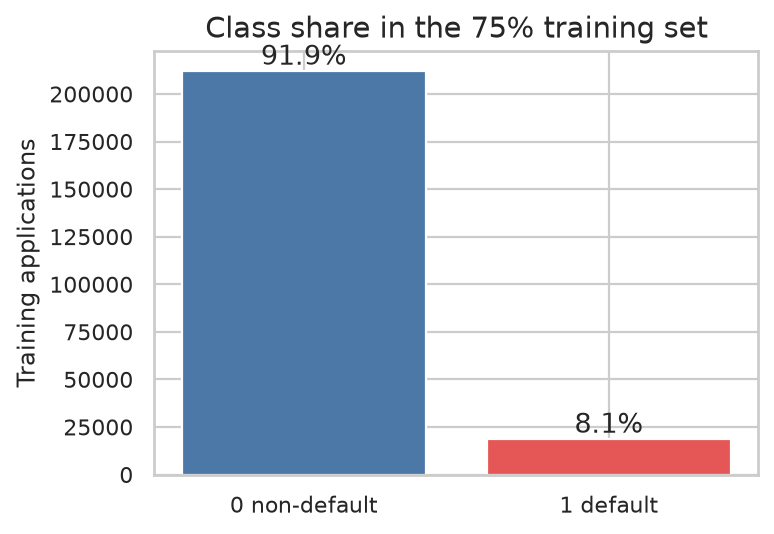

E:\HKUST_DDM\MSDM5054\mini-project\.conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


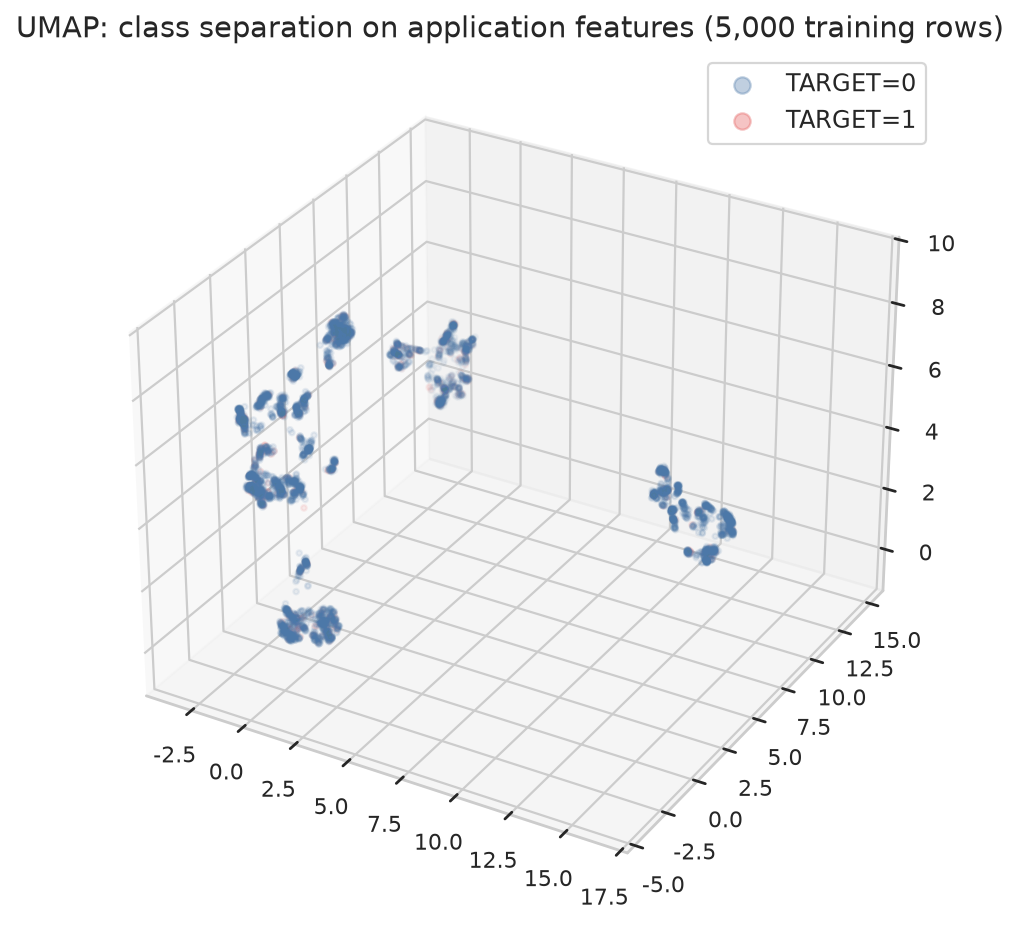

If the two classes overlap, later behavior and sequence features are required. A linear boundary on the application table alone is not enough.


In [10]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = pd.Series(y_train).value_counts().sort_index()
ax.bar(["0 non-default", "1 default"], counts.values, color=["#4C78A8", "#E45756"])
for i, value in enumerate(counts.values):
    ax.text(i, value, "{:.1%}".format(value / counts.sum()), ha="center", va="bottom")
ax.set_ylabel("Training applications")
ax.set_title("Class share in the 75% training set")
plt.tight_layout()
plt.show()

application_columns = [
    c for c in train_df.columns
    if not c.startswith(("bureau_", "prev_", "pos_", "cc_", "inst_", "bb_"))
    and c not in ("SK_ID_CURR", "TARGET", "SET", "NO_BUREAU", "NO_PREVIOUS",
                  "bureau_credit_type_mode", "prev_status_mode", "prev_reject_mode",
                  "prev_product_mode", "prev_yield_mode")
]
app_numeric = [c for c in application_columns if pd.api.types.is_numeric_dtype(train_df[c])]
viz_idx, _ = train_test_split(
    np.arange(len(train_df)), train_size=5000, stratify=y_train, random_state=RANDOM_STATE
)
viz = train_df.iloc[viz_idx][app_numeric].replace([np.inf, -np.inf], np.nan)
viz = viz.fillna(viz.median(numeric_only=True))
viz_qt = QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=RANDOM_STATE)
viz_x = viz_qt.fit_transform(viz)
y_viz = y_train[viz_idx]
try:
    import umap
    embedding = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1).fit_transform(viz_x)
    method_name = "UMAP"
except Exception as exc:
    print("UMAP failed; falling back to PCA.", exc)
    embedding = PCA(n_components=3, random_state=RANDOM_STATE).fit_transform(viz_x)
    method_name = "PCA"

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, color in [(0, "#4C78A8"), (1, "#E45756")]:
    mask = y_viz == label
    ax.scatter(embedding[mask, 0], embedding[mask, 1], embedding[mask, 2], s=6, alpha=0.35, c=color, label="TARGET={}".format(label))
ax.set_title("{}: class separation on application features (5,000 training rows)".format(method_name))
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()
print("If the two classes overlap, later behavior and sequence features are required. A linear boundary on the application table alone is not enough.")


## Models

The three models share one set of five folds. Each model selects a small set of hyperparameters on an inner 20% validation split, then produces out-of-fold probabilities on the five folds. The classification threshold is chosen on out-of-fold probabilities by F1, in steps of 0.01. Models are compared by AUC only.


In [11]:
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(train_df, y_train))
inner_tr, inner_va = train_test_split(
    np.arange(len(train_df)), test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

banned = {"SK_ID_CURR", "TARGET", "SET"}
cat_cols = [
    "NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE",
    "bureau_credit_type_mode", "prev_status_mode", "prev_reject_mode", "prev_product_mode", "prev_yield_mode",
]
lgb_cols = []
for col in train_df.columns:
    if col in banned or col in cat_cols:
        continue
    if pd.api.types.is_numeric_dtype(train_df[col]):
        lgb_cols.append(col)
nunique = train_df[lgb_cols].nunique(dropna=True)
missing = train_df[lgb_cols].isna().mean()
lgb_cols = [c for c in lgb_cols if nunique[c] > 1 and missing[c] <= 0.995]
print("LightGBM feature count:", len(lgb_cols))

X_lgb = train_df[lgb_cols].to_numpy(dtype=np.float32)
X_lgb_hold = holdout_df[lgb_cols].to_numpy(dtype=np.float32)
X_lgb_test = test_df[lgb_cols].to_numpy(dtype=np.float32)

CAT_NUM = [
    c for c in [
        "AGE_YEARS", "EMPLOYED_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
        "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "REGION_RATING_CLIENT",
        "CNT_FAM_MEMBERS", "DOCUMENT_COUNT", "bureau_n", "prev_n", "inst_n", "pos_n",
        "cc_n", "bb_months", "NO_BUREAU", "NO_PREVIOUS", "bureau_debt_ratio",
    ] if c in train_df.columns
]
_extra_prefix = (
    "EXT_SOURCE_1_", "EXT_SOURCE_2_", "EXT_SOURCE_PROD", "EXT_MEAN_", "EXT_MIN_",
    "prev_appr_", "prev_ref_", "prev_last_", "prev_refused_",
    "bb_status_", "bb_late_trend", "bb_months_since",
    "inst_late_trend", "inst_pay_trend", "inst_last_",
    "pos_dpd_trend", "cc_util_trend",
    "bureau_active_debt", "bureau_overdue_days_mean", "bureau_days_credit_mean", "bureau_credit_mean",
)
CAT_NUM += [
    c for c in train_df.columns
    if c.startswith(_extra_prefix) and pd.api.types.is_numeric_dtype(train_df[c]) and c not in CAT_NUM
]
print("CatBoost numeric columns:", len(CAT_NUM))

def cat_frame(df):
    out = df[CAT_NUM + cat_cols].copy()
    for col in cat_cols:
        out[col] = out[col].astype("string").fillna("Missing").astype(str)
    return out

X_cat_train = cat_frame(train_df)
X_cat_hold = cat_frame(holdout_df)
X_cat_test = cat_frame(test_df)

seq_row = pd.Series(np.arange(len(seq_ids)), index=pd.Index(seq_ids.astype(np.int64)))
status_train = status_seq[seq_row.loc[train_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
inst_train = inst_seq[seq_row.loc[train_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
status_hold = status_seq[seq_row.loc[holdout_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
inst_hold = inst_seq[seq_row.loc[holdout_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
status_test = status_seq[seq_row.loc[test_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
inst_test = inst_seq[seq_row.loc[test_df["SK_ID_CURR"].astype(np.int64)].to_numpy()]
STATIC_COLS = ["AGE_YEARS", "EXT_SOURCE_MEAN", "CREDIT_INCOME_RATIO"]
static_train = train_df[STATIC_COLS].to_numpy(dtype=np.float32)
static_hold = holdout_df[STATIC_COLS].to_numpy(dtype=np.float32)
static_test = test_df[STATIC_COLS].to_numpy(dtype=np.float32)

oof_proba, hold_proba, test_proba, thresholds = {}, {}, {}, {}
cv_rows = []

def publish_oof(name, oof, hold, test):
    threshold, _, _, _ = best_f1_threshold(y_train, oof)
    thresholds[name] = threshold
    oof_proba[name] = oof
    hold_proba[name] = hold
    test_proba[name] = test
    print("{} out-of-fold F1 threshold {:.2f}. The metrics below are out-of-fold, not holdout:".format(name, threshold))
    metrics = get_clf_eval(y_train, (oof >= threshold).astype(int), oof)
    cv_rows.append({"model": name, "OOF AUC": metrics["auc"], "OOF F1": metrics["f1"], "F1 threshold": threshold})
    return metrics


LightGBM feature count: 148
CatBoost numeric columns: 58


### LightGBM

LightGBM uses every numeric feature, including burden ratios, recent-versus-full-history differences, and previous applications split into approved and refused. Four parameter sets are compared on the inner validation split. The final fit uses at most 3,000 rounds and stops if validation AUC does not improve for 100 rounds.


Inner validation AUC 0.7798  {'num_leaves': 24, 'min_child_samples': 300, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 1.0, 'learning_rate': 0.05, 'subsample_freq': 1}


Inner validation AUC 0.7806  {'num_leaves': 24, 'min_child_samples': 300, 'subsample': 0.7, 'colsample_bytree': 0.6, 'reg_lambda': 1.0, 'learning_rate': 0.05, 'subsample_freq': 1}


Inner validation AUC 0.7795  {'num_leaves': 48, 'min_child_samples': 300, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'learning_rate': 0.03, 'subsample_freq': 0}


Inner validation AUC 0.7789  {'num_leaves': 48, 'min_child_samples': 150, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 0.1, 'learning_rate': 0.05, 'subsample_freq': 1}


,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,learning_rate,subsample_freq,inner AUC,best iteration
1,24,300,0.70,0.6,1.0,0.05,1,0.7806,464
0,24,300,0.85,0.6,1.0,0.05,1,0.7798,489
2,48,300,1.00,0.8,1.0,0.03,0,0.7795,709
3,48,150,0.85,0.6,0.1,0.05,1,0.7789,487


...

Fold 3 done, best iteration 482


Fold 4 done, best iteration 529


Fold 5 done, best iteration 463


Interaction LightGBM out-of-fold F1 threshold 0.16. The metrics below are out-of-fold, not holdout:


accuracy: 0.8578, precision: 0.2664, recall: 0.4340, F1: 0.3301, AUC: 0.7811


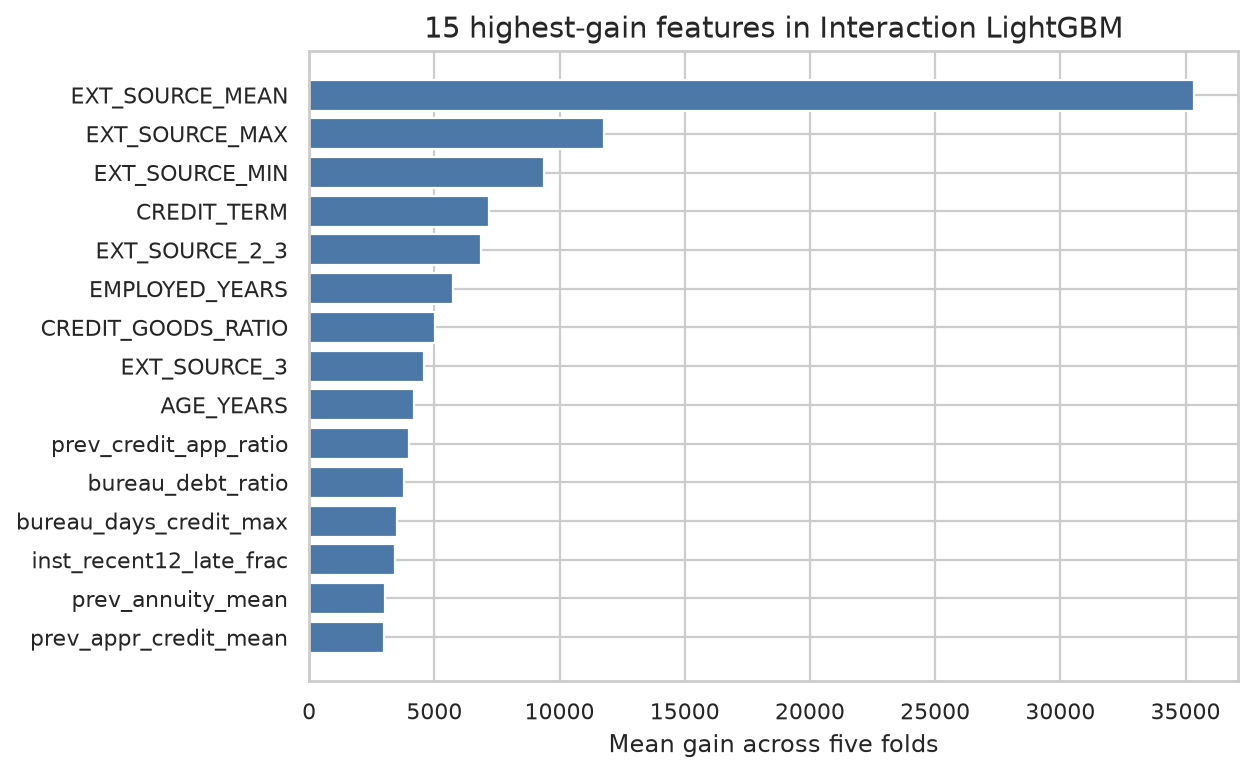

In [12]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

rng = np.random.default_rng(RANDOM_STATE)
trials = []
for _ in range(4):
    params = {
        "num_leaves": int(rng.choice([24, 32, 48])),
        "min_child_samples": int(rng.choice([80, 150, 300])),
        "subsample": float(rng.choice([0.7, 0.85, 1.0])),
        "colsample_bytree": float(rng.choice([0.6, 0.8])),
        "reg_lambda": float(rng.choice([0.1, 1.0, 5.0])),
        "learning_rate": float(rng.choice([0.03, 0.05])),
    }
    params["subsample_freq"] = 1 if params["subsample"] < 1 else 0
    trials.append(params)

def fit_lgbm(params, tr_idx, va_idx, X=None, n_estimators=3000, stopping=100):
    if X is None:
        X = X_lgb
    model = LGBMClassifier(
        objective="binary", n_estimators=n_estimators, max_depth=6, n_jobs=N_JOBS,
        random_state=RANDOM_STATE, verbose=-1, importance_type="gain", **params,
    )
    model.fit(
        X[tr_idx], y_train[tr_idx],
        eval_set=[(X[va_idx], y_train[va_idx])],
        eval_metric="auc",
        callbacks=[early_stopping(stopping, verbose=False), log_evaluation(0)],
    )
    return model

tune_rows = []
for params in trials:
    model = fit_lgbm(params, inner_tr, inner_va, n_estimators=800, stopping=40)
    score = roc_auc_score(y_train[inner_va], model.predict_proba(X_lgb[inner_va])[:, 1])
    tune_rows.append({**params, "inner AUC": score, "best iteration": model.best_iteration_})
    print("Inner validation AUC {:.4f}  {}".format(score, params))
tune_table = pd.DataFrame(tune_rows).sort_values("inner AUC", ascending=False)
display(tune_table.round(4))
best_lgb_params = tune_table.iloc[0][["num_leaves", "min_child_samples", "subsample", "colsample_bytree", "reg_lambda", "learning_rate"]].to_dict()
best_lgb_params = {k: (int(v) if k in ("num_leaves", "min_child_samples") else float(v)) for k, v in best_lgb_params.items()}
best_lgb_params["subsample_freq"] = 1 if best_lgb_params["subsample"] < 1 else 0
print("Selected parameters:", best_lgb_params)

oof = np.zeros(len(train_df))
hold = np.zeros(len(holdout_df))
test = np.zeros(len(test_df))
importance = np.zeros(len(lgb_cols))
for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    model = fit_lgbm(best_lgb_params, tr_idx, va_idx)
    oof[va_idx] = model.predict_proba(X_lgb[va_idx])[:, 1]
    hold += model.predict_proba(X_lgb_hold)[:, 1] / N_FOLDS
    test += model.predict_proba(X_lgb_test)[:, 1] / N_FOLDS
    importance += model.feature_importances_ / N_FOLDS
    print("Fold {} done, best iteration {}".format(fold, model.best_iteration_))
publish_oof("Interaction LightGBM", oof, hold, test)

order = np.argsort(importance)[-15:]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(lgb_cols)[order], importance[order], color="#4C78A8")
ax.set_xlabel("Mean gain across five folds")
ax.set_title("15 highest-gain features in Interaction LightGBM")
plt.tight_layout()
plt.show()


### CatBoost

Categorical fields keep their original values, including occupation, organization, rejection reason, and product combination. Numeric inputs are external scores, burden ratios, and aggregated differences, rather than the full LightGBM column set. Depth is chosen between 4 and 6. The final fit uses at most 2,000 rounds, with early stopping after 80 rounds.


In [13]:
from catboost import CatBoostClassifier

cat_trials = []
for depth in (4, 6):
    model = CatBoostClassifier(
        iterations=800, learning_rate=0.05, depth=depth, loss_function="Logloss",
        eval_metric="AUC", random_seed=RANDOM_STATE, early_stopping_rounds=50,
        thread_count=N_JOBS, verbose=0, allow_writing_files=False,
    )
    model.fit(
        X_cat_train.iloc[inner_tr], y_train[inner_tr], cat_features=cat_cols,
        eval_set=(X_cat_train.iloc[inner_va], y_train[inner_va]), use_best_model=True,
    )
    score = roc_auc_score(y_train[inner_va], model.predict_proba(X_cat_train.iloc[inner_va])[:, 1])
    cat_trials.append({"depth": depth, "inner AUC": score, "best iteration": model.get_best_iteration()})
    print("depth={} inner validation AUC {:.4f}".format(depth, score))
cat_table = pd.DataFrame(cat_trials).sort_values("inner AUC", ascending=False)
display(cat_table.round(4))
best_depth = int(cat_table.iloc[0]["depth"])

oof = np.zeros(len(train_df))
hold = np.zeros(len(holdout_df))
test = np.zeros(len(test_df))
for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    model = CatBoostClassifier(
        iterations=2000, learning_rate=0.05, depth=best_depth, loss_function="Logloss",
        eval_metric="AUC", random_seed=RANDOM_STATE, early_stopping_rounds=80,
        thread_count=N_JOBS, verbose=0, allow_writing_files=False,
    )
    model.fit(
        X_cat_train.iloc[tr_idx], y_train[tr_idx], cat_features=cat_cols,
        eval_set=(X_cat_train.iloc[va_idx], y_train[va_idx]), use_best_model=True,
    )
    oof[va_idx] = model.predict_proba(X_cat_train.iloc[va_idx])[:, 1]
    hold += model.predict_proba(X_cat_hold)[:, 1] / N_FOLDS
    test += model.predict_proba(X_cat_test)[:, 1] / N_FOLDS
    print("Fold {} done, best iteration {}".format(fold, model.get_best_iteration()))
publish_oof("Categorical CatBoost", oof, hold, test)
print("Correlation with Interaction LightGBM out-of-fold probabilities: {:.4f}".format(np.corrcoef(oof_proba["Interaction LightGBM"], oof_proba["Categorical CatBoost"])[0, 1]))


depth=4 inner validation AUC 0.7648


depth=6 inner validation AUC 0.7673


,depth,inner AUC,best iteration
1,6,0.7673,796
0,4,0.7648,798


Fold 1 done, best iteration 1395


Fold 2 done, best iteration 1178


Fold 3 done, best iteration 1128


Fold 4 done, best iteration 1287


Fold 5 done, best iteration 987


Categorical CatBoost out-of-fold F1 threshold 0.15. The metrics below are out-of-fold, not holdout:
accuracy: 0.8505, precision: 0.2531, recall: 0.4362, F1: 0.3203, AUC: 0.7701
Correlation with Interaction LightGBM out-of-fold probabilities: 0.8780


### LightGBM with trajectory probabilities

The trajectory model produces a single probability column and is not compared on its own. Each applicant uses the latest 24 months of bureau status, the latest 24 installments of days late and paid-to-due ratio, plus age, the mean external score, and credit-to-income. Two GRUs with hidden size 16 read the sequences. That out-of-fold probability is appended to the LightGBM features, and LightGBM is trained again on the same five folds. On each validation fold, the trajectory probability comes from a model that has not seen that fold.


In [14]:
import copy
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

class TrajectoryNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.status_emb = nn.Embedding(7, 8, padding_idx=0)
        self.status_gru = nn.GRU(8, 16, batch_first=True)
        self.inst_gru = nn.GRU(3, 16, batch_first=True)
        self.static_fc = nn.Linear(3, 8)
        self.head = nn.Sequential(nn.Linear(40, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, status, inst, static):
        _, h_status = self.status_gru(self.status_emb(status.long()))
        _, h_inst = self.inst_gru(torch.nan_to_num(inst, nan=0.0))
        h_static = self.static_fc(torch.nan_to_num(static, nan=0.0))
        hidden = torch.cat([h_status[-1], h_inst[-1], h_static], dim=1)
        return self.head(hidden).squeeze(1)


def static_stats(static, idx):
    med = np.nanmedian(static[idx], axis=0)
    med = np.where(np.isnan(med), 0, med)
    return med.astype(np.float32)

def apply_static(static, med):
    filled = static.copy()
    inds = np.where(np.isnan(filled))
    filled[inds] = np.take(med, inds[1])
    mu = np.nanmean(filled, axis=0) if False else None
    return filled

def scale_static(train_static, other_statics):
    med = np.nanmedian(train_static, axis=0)
    med = np.where(np.isnan(med), 0, med).astype(np.float32)
    def fill(arr):
        out = arr.copy()
        inds = np.where(np.isnan(out))
        out[inds] = np.take(med, inds[1])
        return out
    filled_train = fill(train_static)
    mu = filled_train.mean(axis=0)
    sd = filled_train.std(axis=0)
    sd = np.where(sd < 1e-6, 1, sd)
    def norm(arr):
        return ((fill(arr) - mu) / sd).astype(np.float32)
    return norm(train_static), [norm(arr) for arr in other_statics]


def fit_sequence(tr_idx, va_idx, fold_id):
    torch.manual_seed(RANDOM_STATE + fold_id)
    z_tr, (z_va,) = scale_static(static_train[tr_idx], [static_train[va_idx]])
    model = TrajectoryNet()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    dataset = TensorDataset(
        torch.from_numpy(status_train[tr_idx].astype(np.int64)),
        torch.from_numpy(np.nan_to_num(inst_train[tr_idx], nan=0.0).astype(np.float32)),
        torch.from_numpy(z_tr),
        torch.from_numpy(y_train[tr_idx].astype(np.float32)),
    )
    loader = DataLoader(dataset, batch_size=4096, shuffle=True)
    best_auc, best_state, wait = -1.0, None, 0
    for epoch in range(1, 5):
        model.train()
        for status_b, inst_b, static_b, y_b in loader:
            optimizer.zero_grad()
            loss = nn.functional.binary_cross_entropy_with_logits(model(status_b, inst_b, static_b), y_b)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        proba = predict_sequence(model, status_train[va_idx], inst_train[va_idx], z_va)
        score = roc_auc_score(y_train[va_idx], proba)
        if score > best_auc + 1e-4:
            best_auc, best_state, wait = score, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        if wait >= 2:
            break
    model.load_state_dict(best_state)
    return model, best_auc


def predict_sequence(model, status, inst, static, batch=4096):
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(status), batch):
            stop = start + batch
            logit = model(
                torch.from_numpy(status[start:stop].astype(np.int64)),
                torch.from_numpy(np.nan_to_num(inst[start:stop], nan=0.0).astype(np.float32)),
                torch.from_numpy(static[start:stop].astype(np.float32)),
            )
            outputs.append(torch.sigmoid(logit).numpy())
    return np.concatenate(outputs)


oof = np.zeros(len(train_df))
hold = np.zeros(len(holdout_df))
test = np.zeros(len(test_df))
for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    model, score = fit_sequence(tr_idx, va_idx, fold)
    z_tr, (z_va, z_hold, z_test) = scale_static(
        static_train[tr_idx], [static_train[va_idx], static_hold, static_test]
    )
    oof[va_idx] = predict_sequence(model, status_train[va_idx], inst_train[va_idx], z_va)
    hold += predict_sequence(model, status_hold, inst_hold, z_hold) / N_FOLDS
    test += predict_sequence(model, status_test, inst_test, z_test) / N_FOLDS
    print("Fold {} validation AUC {:.4f}".format(fold, score))
oof_proba["trajectory"] = oof
hold_proba["trajectory"] = hold
test_proba["trajectory"] = test
print("Trajectory out-of-fold AUC {:.4f}".format(roc_auc_score(y_train, oof)))


Fold 1 validation AUC 0.7134


Fold 2 validation AUC 0.7117


Fold 3 validation AUC 0.7222


Fold 4 validation AUC 0.7182


Fold 5 validation AUC 0.7143
Trajectory out-of-fold AUC 0.7159


In [15]:
seq_name = "trajectory"
X_seq = np.column_stack([X_lgb, oof_proba[seq_name]]).astype(np.float32)
X_seq_hold = np.column_stack([X_lgb_hold, hold_proba[seq_name]]).astype(np.float32)
X_seq_test = np.column_stack([X_lgb_test, test_proba[seq_name]]).astype(np.float32)
oof = np.zeros(len(train_df))
hold = np.zeros(len(holdout_df))
test = np.zeros(len(test_df))
for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    model = fit_lgbm(best_lgb_params, tr_idx, va_idx, X=X_seq, n_estimators=3000, stopping=100)
    oof[va_idx] = model.predict_proba(X_seq[va_idx])[:, 1]
    hold += model.predict_proba(X_seq_hold)[:, 1] / N_FOLDS
    test += model.predict_proba(X_seq_test)[:, 1] / N_FOLDS
    print("Fold {} done, best iteration {}".format(fold, model.best_iteration_))
publish_oof("LightGBM+trajectory", oof, hold, test)


Fold 1 done, best iteration 471


Fold 2 done, best iteration 645


Fold 3 done, best iteration 667


Fold 4 done, best iteration 447


Fold 5 done, best iteration 614


LightGBM+trajectory out-of-fold F1 threshold 0.16. The metrics below are out-of-fold, not holdout:


accuracy: 0.8577, precision: 0.2663, recall: 0.4344, F1: 0.3302, AUC: 0.7817


{'accuracy': 0.8576916573083644,
 'precision': 0.2662606978275181,
 'recall': 0.4344486814544283,
 'f1': 0.3301700034694586,
 'auc': 0.7816744941098712,
 'confusion': array([[189723,  22291],
        [ 10530,   8089]])}

### Stacking

Logistic regression is trained on the three models' out-of-fold probabilities, inside the same five folds: on each fold the stacker sees only the probabilities from the other four folds. If the stacker's out-of-fold AUC is at least as high as the best single model, the final probability is the stacker. Otherwise it is the best single model.


In [16]:
names = ["Interaction LightGBM", "Categorical CatBoost", "LightGBM+trajectory"]
print("Out-of-fold AUC")
for name in names:
    print("  {:22s} {:.4f}".format(name, roc_auc_score(y_train, oof_proba[name])))

matrix = np.column_stack([oof_proba[name] for name in names])
stacked = np.zeros(len(y_train))
for tr_idx, va_idx in folds:
    stacker = LogisticRegression(max_iter=400)
    stacker.fit(matrix[tr_idx], y_train[tr_idx])
    stacked[va_idx] = stacker.predict_proba(matrix[va_idx])[:, 1]

final_stacker = LogisticRegression(max_iter=400)
final_stacker.fit(matrix, y_train)
hold_stack = final_stacker.predict_proba(np.column_stack([hold_proba[name] for name in names]))[:, 1]
test_stack = final_stacker.predict_proba(np.column_stack([test_proba[name] for name in names]))[:, 1]
print("Stacker coefficients")
for name, coef in zip(names, final_stacker.coef_.ravel()):
    print("  {:22s} {:+.3f}".format(name, coef))
publish_oof("Stacker", stacked, hold_stack, test_stack)

best_single = max(names, key=lambda name: roc_auc_score(y_train, oof_proba[name]))
if roc_auc_score(y_train, oof_proba["Stacker"]) >= roc_auc_score(y_train, oof_proba[best_single]):
    final_name = "Stacker"
else:
    final_name = best_single
print("Final probability:", final_name)
display(pd.DataFrame(cv_rows).drop_duplicates("model", keep="last").sort_values("OOF AUC", ascending=False).round(4))


Out-of-fold AUC
  Interaction LightGBM   0.7811


  Categorical CatBoost   0.7701


  LightGBM+trajectory    0.7817


Stacker coefficients
  Interaction LightGBM   +2.950
  Categorical CatBoost   +2.572
  LightGBM+trajectory    +2.991


Stacker out-of-fold F1 threshold 0.11. The metrics below are out-of-fold, not holdout:


accuracy: 0.8514, precision: 0.2613, recall: 0.4598, F1: 0.3332, AUC: 0.7841


Final probability: Stacker


,model,OOF AUC,OOF F1,F1 threshold
3,Stacker,0.7841,0.3332,0.11
2,LightGBM+trajectory,0.7817,0.3302,0.16
0,Interaction LightGBM,0.7811,0.3301,0.16
1,Categorical CatBoost,0.7701,0.3203,0.15


## Results

The table below is the only evaluation on the holdout set. Thresholds come from out-of-fold probabilities. AUC does not depend on the threshold.


Holdout set
Interaction LightGBM  threshold 0.16
accuracy: 0.8599, precision: 0.2731, recall: 0.4425, F1: 0.3377, AUC: 0.7867
Categorical CatBoost  threshold 0.15


accuracy: 0.8529, precision: 0.2604, recall: 0.4467, F1: 0.3290, AUC: 0.7767
LightGBM+trajectory  threshold 0.16


accuracy: 0.8600, precision: 0.2731, recall: 0.4418, F1: 0.3375, AUC: 0.7865
Stacker  threshold 0.11
accuracy: 0.8530, precision: 0.2658, recall: 0.4657, F1: 0.3384, AUC: 0.7884


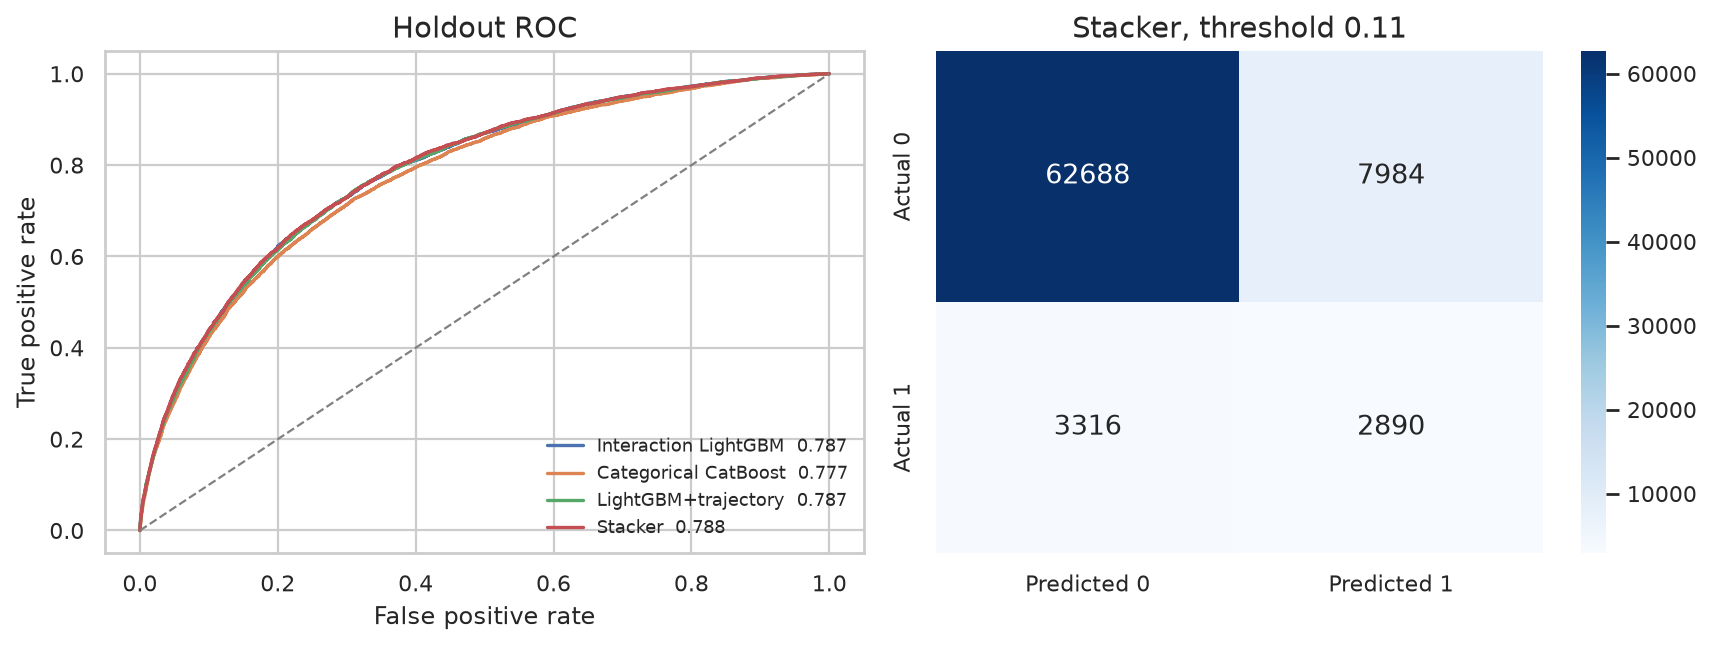

,model,AUC,F1,threshold
0,Interaction LightGBM,0.7867,0.3377,0.16
1,Categorical CatBoost,0.7767,0.3290,0.15
2,LightGBM+trajectory,0.7865,0.3375,0.16
3,Stacker,0.7884,0.3384,0.11


Final probability: Stacker


In [17]:
print("Holdout set")
rows = []
order = ["Interaction LightGBM", "Categorical CatBoost", "LightGBM+trajectory", "Stacker"]
for name in order:
    proba = hold_proba[name]
    threshold = thresholds[name]
    print("{}  threshold {:.2f}".format(name, threshold))
    metrics = get_clf_eval(y_hold, (proba >= threshold).astype(int), proba)
    rows.append({"model": name, "AUC": metrics["auc"], "F1": metrics["f1"], "threshold": threshold})

final_proba = hold_proba[final_name]
final_pred = (final_proba >= thresholds[final_name]).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name in order:
    fpr, tpr, _ = roc_curve(y_hold, hold_proba[name])
    axes[0].plot(fpr, tpr, label="{}  {:.3f}".format(name, roc_auc_score(y_hold, hold_proba[name])))
axes[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("Holdout ROC")
axes[0].legend(fontsize=8, frameon=False)
sns.heatmap(
    confusion_matrix(y_hold, final_pred), annot=True, fmt="d", cmap="Blues", ax=axes[1],
    xticklabels=["Predicted 0", "Predicted 1"], yticklabels=["Actual 0", "Actual 1"],
)
axes[1].set_title("{}, threshold {:.2f}".format(final_name, thresholds[final_name]))
plt.tight_layout()
plt.show()

summary = pd.DataFrame(rows)
summary.to_csv(OUTPUT_DIR / "holdout_metrics.csv", index=False)
submission = pd.DataFrame({
    "SK_ID_CURR": test_df["SK_ID_CURR"].astype(int),
    "TARGET": test_proba[final_name],
})
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
display(summary.round(4))
print("Final probability:", final_name)


The three models rank close together. The stacker uses their out-of-fold probabilities and supplies the final holdout result. The trajectory probability is not compared on its own; it is only one input column of the third LightGBM. The positive class is about 8%, so the F1-optimal threshold is below 0.5.
